# Pre-processing (occupancy)

**Functions:** the building's occupancy sensors produce one big spreadsheet (a CSV file) mixing
several rooms together. This notebook checks that the file looks exactly as expected, then splits it into one small
file per room, keeping only the two columns we need: the headcount and the time. The room is identified by the file's name.

**Rule:** if a file's column headings are not exactly the expected ones, the code stops with an error instead of guessing.

| Step | Function | What goes in | What comes out |
|---|---|---|---|
| 1 | `check_headings` | a CSV file | nothing, or an error if the headings are wrong |
| 2 | `find_occupancy_file` | the `data` folder | the newest occupancy file in it |
| 3 | `clean_headcount` | a column of headcounts as text | the same counts as numbers |
| 4 | `split_by_room` | the occupancy file | one CSV per room (room ID still included) + a summary |
| 5 | `drop_room_id` | the folder of room files | the same files without the room ID column |
| 6a | `ids_in_folder` | a folder of room files or models | the room IDs found in it |
| 6b | `read_lookup` | the room lookup files | one combined table of room names and IDs (newest file wins) |
| 6c | `store_lookup` | a supplied lookup file | a checked copy kept in the `lookups` folder |
| 6d | `find_unnamed_ids` | the lookup files + available IDs | IDs that have data or models but no room name yet |
| 6e | `find_floorspace_ids` | room names + the lookup files + available IDs | the floorspace ID of each covered room (others are reported) |
| 7 | run | the `data` folder and room names | everything in `derived/preprocessed/`, plus the chosen rooms' IDs |

In [103]:
# Setup: folders and the exact column headings we expect. Run from the project's main folder.
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path.cwd() / "data"
OUTPUT_DIR = Path.cwd() / "derived" / "preprocessed"

# Room lookups supplied by the user are kept here, and every lookup in these folders is used.
LOOKUPS_DIR = Path.cwd() / "lookups"
LOOKUP_FOLDERS = [DATA_DIR, Path.cwd(), LOOKUPS_DIR]

# Files are read in pieces of this many rows so the computer's memory is never overloaded.
ROWS_PER_PIECE = 50_000

# The exact headings (and order) of a raw occupancy file.
RAW_HEADINGS = ["id", "deviceid", "floorspaceid", "occupancystatus", "headcount",
                "collecteddate", "occupancystatuschangedate", "previousoccupancystatus"]

# The exact headings of the room lookup file.
LOOKUP_HEADINGS = ["Building", "Floor/Room", "Area", "ID", "Note", "FloorId", "SpaceId"]

# The columns we read from the raw file. The row "id" is never used, so it is not even read.
KEPT_HEADINGS = ["floorspaceid", "headcount", "collecteddate"]

# The final columns of each room's file. The room ID is only needed to split the rooms apart.
FINAL_HEADINGS = ["headcount", "collecteddate"]

In [104]:
def check_headings(csv_file, expected_headings):
    """Stop with an error if a file's column headings are not exactly as expected.

    Only the heading row is read, so this is fast even for huge files.

    Input:
        csv_file: the file to check.
        expected_headings: the list of headings the file must have, in order.

    Output:
        Nothing if the headings match exactly.

    Errors:
        ValueError if any heading is missing, extra, renamed or in a different order.
    """
    found = list(pd.read_csv(csv_file, nrows=0).columns)
    if found != list(expected_headings):
        raise ValueError(f"{Path(csv_file).name} has the wrong column headings.\n"
                         f"  Expected: {list(expected_headings)}\n  Found:    {found}")

In [105]:
def find_occupancy_file(data_folder):
    """Find the newest occupancy file inside the data folder (including sub-folders).

    A CSV is treated as occupancy data if it contains a "floorspaceid" heading.
    Other kinds of CSV files in the folder are ignored. If an occupancy file has the
    wrong headings, the code stops with an error rather than using it.

    Input:
        data_folder: the folder that holds the raw data files.

    Output:
        The path of the most recently modified occupancy file.

    Errors:
        FileNotFoundError if no occupancy file is found.
        ValueError if an occupancy file has the wrong headings.
    """
    candidates = []
    for path in sorted(Path(data_folder).rglob("*.csv")):
        if "floorspaceid" in pd.read_csv(path, nrows=0).columns:
            check_headings(path, RAW_HEADINGS)
            candidates.append(path)
    if not candidates:
        raise FileNotFoundError(f"No occupancy file found in {data_folder}")
    return max(candidates, key=lambda p: p.stat().st_mtime_ns)

In [106]:
def clean_headcount(headcounts):
    """Turn a column of headcounts (text) into numbers, leaving blanks as "missing".

    A blank (or the words nan / null / none) becomes a missing value, never zero.

    Input:
        headcounts: a column of headcounts as text.

    Output:
        The same column as numbers, with missing values left empty.

    Errors:
        ValueError if any entry is not a whole number of 0 or more.
    """
    text = headcounts.str.strip().str.casefold()
    is_blank = text.isin(["", "nan", "null", "none"])
    numbers = pd.to_numeric(text.mask(is_blank), errors="coerce")
    if (numbers.isna() & ~is_blank).any() or (numbers < 0).any() or ((numbers % 1) != 0).any():
        raise ValueError("Headcounts must be whole numbers of 0 or more (or blank).")
    return numbers

In [107]:
def split_by_room(occupancy_file, output_folder):
    """Check the occupancy file and split it into one CSV file per room.

    Every row is kept (nothing is deleted). The unused "id" column is dropped straight
    away; the room ID is kept for now and removed later by drop_room_id. Old room
    files already in the output folder are replaced.

    Checks made on every row: the room ID is not blank, the collection date is a
    real date, and the headcount is valid (see clean_headcount).

    Input:
        occupancy_file: the raw occupancy CSV (must have exactly RAW_HEADINGS).
        output_folder: where the room files are saved (created if needed).

    Output:
        A table with one line per room and its number of rows, which is also saved
        as "rows_per_room.csv" in the output folder.

    Errors:
        ValueError if the headings are wrong, a check fails, or the file is empty.
    """
    check_headings(occupancy_file, RAW_HEADINGS)
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)
    for old_file in output_folder.glob("*.csv"):
        old_file.unlink()

    rows_per_room = {}
    for piece in pd.read_csv(occupancy_file, usecols=KEPT_HEADINGS, dtype=str,
                             keep_default_na=False, chunksize=ROWS_PER_PIECE):
        if (piece["floorspaceid"].str.strip() == "").any():
            raise ValueError("Found a row with no room ID.")
        if pd.to_datetime(piece["collecteddate"], errors="coerce", utc=True).isna().any():
            raise ValueError("Found a row with an invalid collection date.")
        piece["headcount"] = clean_headcount(piece["headcount"])
        for room, rows in piece[KEPT_HEADINGS].groupby("floorspaceid"):
            room_file = output_folder / f"{room}.csv"
            rows.to_csv(room_file, mode="a", header=not room_file.exists(), index=False)
            rows_per_room[room] = rows_per_room.get(room, 0) + len(rows)

    if not rows_per_room:
        raise ValueError("The occupancy file contains no data rows.")
    summary = pd.DataFrame({"room_id": list(rows_per_room), "rows": list(rows_per_room.values())})
    summary.to_csv(output_folder / "rows_per_room.csv", index=False)
    return summary

In [108]:
def drop_room_id(room_folder):
    """Remove the room ID column from every room file, leaving only headcount and time.

    This is the very last step. Each file's name is still the room ID, so no
    information about which room it belongs to is lost. "rows_per_room.csv" is left alone.

    Input:
        room_folder: the folder of room files made by split_by_room.

    Output:
        Nothing. The files are rewritten in place.

    Errors:
        ValueError if a room file does not have the expected headings.
    """
    for room_file in Path(room_folder).glob("*.csv"):
        if room_file.name == "rows_per_room.csv":
            continue
        check_headings(room_file, KEPT_HEADINGS)
        temporary = room_file.with_suffix(".tmp")
        for number, piece in enumerate(pd.read_csv(room_file, usecols=FINAL_HEADINGS, dtype=str,
                                                   keep_default_na=False, chunksize=ROWS_PER_PIECE)):
            piece[FINAL_HEADINGS].to_csv(temporary, mode="a" if number else "w", header=not number, index=False)
        temporary.replace(room_file)

In [109]:
def ids_in_folder(folder):
    """List the floorspace IDs that have a file (preprocessing) or a sub-folder (models) in a folder.

    Input:
        folder: a folder of room files (e.g. occupancy_streams) or of model folders.

    Output:
        A set of floorspace IDs. Empty if the folder does not exist. "rows_per_room.csv"
        is not a room and is ignored.
    """
    folder = Path(folder)
    if not folder.is_dir():
        return set()
    return {p.stem if p.is_file() else p.name for p in folder.iterdir()
            if p.name != "rows_per_room.csv" and (p.is_dir() or p.suffix == ".csv")}

In [110]:
def read_lookup(lookup_folders, report=False):
    """Read every room lookup file and combine them into one table of room names and floorspace IDs.

    Lookup files are the files whose name starts with "Sensor ID and Locations - OCC"
    in the given folders (this includes every lookup stored by store_lookup). Rows
    with a blank room name or floorspace ID are ignored. If several files mention the
    same room, the newest file (by its last-modified time) decides which ID(s) the room
    has, and the older files' entries for that room are ignored.

    Input:
        lookup_folders: folders to search for lookup files.
        report: if True, print a note for every room whose IDs were replaced by a newer file.

    Output:
        A table with the columns room, id, source (the file the entry came from) and
        entry (the name a user picks: the room name, or for a room with several
        floorspace IDs, e.g. "1.61 (ID ending 5c3a)", one entry per ID), one line per
        room and floorspace ID.

    Errors:
        FileNotFoundError if no lookup file is found.
        ValueError if any lookup file has the wrong headings.
    """
    files = sorted({p for folder in lookup_folders for p in Path(folder).glob("Sensor ID and Locations - OCC*.csv")},
                   key=lambda p: (p.stat().st_mtime_ns, p.name))
    if not files:
        raise FileNotFoundError("Room lookup file (Sensor ID and Locations - OCC...) not found.")
    newest = {}
    for path in files:
        check_headings(path, LOOKUP_HEADINGS)
        table = pd.read_csv(path, dtype=str, keep_default_na=False)
        table = pd.DataFrame({"room": table["Floor/Room"].str.strip(), "id": table["SpaceId"].str.strip()})
        table = table[(table["room"] != "") & (table["id"] != "")]
        for key, group in table.groupby(table["room"].str.casefold()):
            ids = sorted(set(group["id"]))
            if report and key in newest and newest[key]["ids"] != ids:
                print(f"NOTE: room {group['room'].iloc[0]!r}: {path.name} replaces the IDs from {newest[key]['source']}.")
            newest[key] = {"room": group["room"].iloc[0], "ids": ids, "source": path.name}
    rows = []
    for entry in newest.values():
        ids = entry["ids"]
        length = 4
        while len({i[-length:] for i in ids}) < len(ids) and length < min(len(i) for i in ids):
            length += 1
        for one_id in ids:
            # A room with several floorspace IDs gets one entry per ID, told apart by the end of the ID.
            name = entry["room"] if len(ids) == 1 else f"{entry['room']} (ID ending {one_id[-length:]})"
            rows.append({"room": entry["room"], "id": one_id, "source": entry["source"], "entry": name})
    return pd.DataFrame(rows, columns=["room", "id", "source", "entry"])

In [111]:
def store_lookup(lookup_file, lookups_folder):
    """Check a supplied room lookup file and keep a copy of it for future runs.

    The copy is saved in the lookups folder under a new name (with the date and time),
    so nothing already stored is overwritten. A file identical to one already stored is
    not copied again, but counts as the newest again.

    Input:
        lookup_file: a room lookup CSV with exactly the lookup headings.
        lookups_folder: where lookups are kept (created if needed).

    Output:
        The path of the stored copy.

    Errors:
        ValueError if the headings are wrong. FileNotFoundError if the file is missing.
    """
    check_headings(lookup_file, LOOKUP_HEADINGS)
    folder = Path(lookups_folder)
    folder.mkdir(parents=True, exist_ok=True)
    content = Path(lookup_file).read_bytes()
    for stored in folder.glob("*.csv"):
        if stored.read_bytes() == content:
            stored.touch()
            print(f"This lookup is already stored ({stored.name}); it now counts as the newest.")
            return stored
    stamp = pd.Timestamp.now().strftime("%Y%m%d-%H%M%S")
    target = folder / f"Sensor ID and Locations - OCC (stored {stamp} from {Path(lookup_file).stem}).csv"
    target.write_bytes(content)
    print(f"Stored the lookup as {target.name}")
    return target

In [112]:
def find_unnamed_ids(lookup_folders, available_ids):
    """List floorspace IDs that have data or models but no room name in any lookup.

    Their models are kept, and they become usable as soon as a lookup names them.

    Input:
        lookup_folders: folders to search for lookup files.
        available_ids: the floorspace IDs that have data or models (see ids_in_folder).

    Output:
        A sorted list of floorspace IDs.
    """
    return sorted(set(available_ids) - set(read_lookup(lookup_folders)["id"]))

In [113]:
def find_floorspace_ids(room_names, lookup_folders, available_ids):
    """Turn room names (e.g. "G.20") into the floorspace IDs used in the occupancy data.

    Each name is matched against the room names of all lookup files combined (see
    read_lookup; the newest file wins if they disagree). Capital letters and spaces
    around a name do not matter. A room is "covered" if it has a floorspace ID in the
    lookup AND that ID is in the list of available IDs (rooms that have data or a
    saved model). Rooms that are not covered are reported in a message and skipped, so
    the analysis can carry on with the rooms that are covered.

    Input:
        room_names: the rooms the user is interested in, e.g. ["G.20", "G.25"].
        lookup_folders: folders to search for lookup files.
        available_ids: the floorspace IDs that have data or models (see ids_in_folder).

    Output:
        A dictionary of {room name: floorspace ID} for the covered rooms only.

    Errors:
        FileNotFoundError if no lookup file is found.
        ValueError if a lookup's headings are wrong, a room name has several floorspace
            IDs (the error lists the choices, e.g. "1.61 (ID ending 5c3a)"), or none of
            the requested rooms are covered.
    """
    lookup = read_lookup(lookup_folders)
    lookup_names = lookup["entry"].str.casefold()

    covered = {}
    for room in room_names:
        ids = sorted(set(lookup.loc[lookup_names == room.strip().casefold(), "id"]))
        if not ids:
            options = sorted(set(lookup.loc[lookup["room"].str.casefold() == room.strip().casefold(), "entry"]))
            if options:
                raise ValueError(f"Room {room!r} has several floorspace IDs. Choose one of: {options}")
        if not ids:
            print(f"REJECTED: {room!r} has no matching data (no floorspace ID for it in the lookup files).")
        elif ids[0] not in set(available_ids):
            print(f"REJECTED: {room!r} has no matching data (its floorspace ID {ids[0]} has no readings or model).")
        else:
            covered[room] = ids[0]
    if not covered:
        raise ValueError("No matching data: none of the requested rooms have a floorspace ID with data, so there is nothing to analyse.")
    return covered

In [114]:
# Run the whole preprocessing: the only input is the data folder.
occupancy_file = find_occupancy_file(DATA_DIR)
summary = split_by_room(occupancy_file, OUTPUT_DIR / "occupancy_streams")
drop_room_id(OUTPUT_DIR / "occupancy_streams")
print(f"Used: {occupancy_file.name}")
print(f"Rooms: {len(summary)}   Rows: {summary['rows'].sum():,}")
print(summary.to_string(index=False))

# Choose rooms by name (the "Floor/Room" column of the lookup file). Uncovered rooms are reported and skipped.
ROOM_NAMES = ["G.20", "G.25", "G.40"]
floorspace_ids = find_floorspace_ids(ROOM_NAMES, LOOKUP_FOLDERS, ids_in_folder(OUTPUT_DIR / "occupancy_streams"))
for room, floorspace_id in floorspace_ids.items():
    print(f"Room {room} -> floorspace ID {floorspace_id}")

Used: 5occupancySensor_MayToDec2024_9MRows.csv
Rooms: 5   Rows: 9,091,732
                             room_id    rows
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7 2169461
941f0352-bb69-47d0-a9c5-ac29eb4f7319 1975423
227f1068-9e41-469f-bef0-275f27a0bdba 1500394
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b 1894871
3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8 1551583
REJECTED: 'G.40' has no matching data (no floorspace ID for it in the lookup files).
Room G.20 -> floorspace ID cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b
Room G.25 -> floorspace ID 227f1068-9e41-469f-bef0-275f27a0bdba


# Analysis

**What the analysis does.** Give it a room name and a time (written `YYYY-MM-DD HH:MM`, Melbourne time) and it returns the
expected headcount. It works from a *model* of the room for the period the time falls in.

1. **Periods.** Every semester has its own pattern of classes, so each calendar year is separated into three periods
   using the dates in `Semester Calendar.csv`:

| Period | Covers |
|---|---|
| `semester_1` | Semester 1 teaching weeks (the mid-semester break is not included) |
| `semester_2` | Semester 2 teaching weeks (the mid-semester break is not included) |
| `non_teaching` | every other day of the year: before Semester 1, both mid-semester breaks, the mid-year break, after Semester 2 |

   All the calendar's dates are used. Pooling all non-teaching days is a choice for broad applicability, tested in
   `archive\investigations\06_holiday_pooling` and `07_midsem_break_grouping`.

2. **Models.** The 15-minute-slot averages of each date (headcount against time of day) are fitted with one RBF
   support-vector regression (SVR) for each weekday of one period of one year. The settings are fixed (C = 0.3, kernel
   length 2 hours, epsilon = 0.1; see `archive\investigations\05_svr_vs_tree_tuning`). A saved model is the regression's support
   vectors, so the raw data is not needed to answer. A weekday with fewer than 3 dates in a period has no model. Models are
   saved in the `models` folder.
3. **Asking.** When a time is asked for, the regression for its weekday is evaluated at that time (never below 0). The
   workflow is: (1) a pop-up asks for two optional files: new headcount data and an updated room
   lookup; (2) a supplied lookup is checked and kept in the `lookups` folder (never overwriting anything), and all
   stored lookups are used together, the newest winning if they disagree about a room, so a room named later can use
   models that already exist for its floorspace ID; (3) with no new data, the rooms that already have a saved model
   are offered straight away; with new data, the file is checked and processed first and the rooms found in it are
   offered; (4) a pop-up asks for the room (from the list) and the time; (5) with new data, the
   models are built from it and saved beside the existing ones (named after the new file) without replacing them, then the
   answer is read from the right model. If a model is missing the code says what is needed.

A year that is not in the calendar file is reported and skipped. Times are read in Melbourne time.

| Step | Function | What goes in | What comes out |
|---|---|---|---|
| A1 | `read_semester_calendar` | the calendar file | the semester and break dates for each year |
| A2 | `label_periods` | reading times + the calendar | the period name of each reading |
| A3 | `read_room_data` | one room's data file | the readings in time order, and their Melbourne times |
| A4 | `split_into_periods` | one room's data + the calendar | one CSV per year and period (for checking the split) |
| A5 | `slot_means` / `fit_svr` / `predict_svr` | times and headcounts / slot means | 15-minute slot means per date / the fitted regression / its headcounts |
| A5b | `make_model` / `evaluate_model` | times and headcounts / a saved model + a time | the saved support vectors per weekday / the headcount at that time |
| A6 | `build_models` | one room's data + the calendar | a saved model per year and period |
| A7 | `read_time` | a time written as text | the time, checked, in Melbourne time |
| A8 | `find_period` | a time + the calendar | the year and period of that time |
| A9 | `get_headcount` | a room name, a time, and optionally processed new data | the headcount (new data makes extra models; saved ones are kept) |
| A10 | `list_rooms` | the lookup files (+ optionally which IDs are available) | the rooms that can be chosen |
| A11 | `load_new_data` | a new data file | its rooms, named, with the data checked and processed |
| A12 | `ask_files` | nothing (a pop-up window asks) | the new headcount file and/or lookup file, both optional |
| A13 | `ask_inputs` | the list of rooms (a pop-up window asks) | the room (picked from a list) and the time |
| A14 | run | the covered rooms | the models, then the pop-ups and the answer |

In [115]:
# Analysis setup.
import tempfile

TIMEZONE = "Australia/Melbourne"
MODELS_DIR = Path.cwd() / "models"

# The exact headings of the semester calendar file. The break dates are the mid-semester break.
CALENDAR_HEADINGS = ["year", "semester", "start_date", "end_date", "break_start", "break_end"]

# The three periods of a year: the two semesters' teaching weeks and everything else.
PERIOD_NAMES = ["semester_1", "semester_2", "non_teaching"]

# The exact headings of a saved model file. A model holds, for each weekday, the support vectors of one RBF regression.
MODEL_HEADINGS = ["weekday", "support_hour", "dual_coef", "intercept"]
SLOT_MINUTES = 15
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Fixed regression settings, chosen and tuned in archive\investigations\05_svr_vs_tree_tuning (no user input needed).
SVR_C = 0.3               # penalty for errors outside the epsilon band (headcount units)
SVR_LENGTH_HOURS = 2.0    # kernel length scale: readings further apart than this have little influence on each other
SVR_EPSILON = 0.1         # errors smaller than this (in people) are ignored
SVR_MIN_DATES = 3         # fewest dates a weekday needs to be modelled or scored
SVR_FOLDS = 4             # cross-validation folds when scoring (reduced to the number of dates if fewer)

# How a time must be written when asking for a headcount.
TIME_FORMAT = "%Y-%m-%d %H:%M"

In [116]:
def read_semester_calendar(calendar_folders):
    """Read the semester dates for each year from the calendar file.

    The file is called "Semester Calendar.csv" and has one line per semester:
    year, semester (1 or 2), start_date (first day of week 1), end_date (last day
    of week 12), and break_start / break_end (the mid-semester break). Dates are
    written as YYYY-MM-DD. A year needs both its semesters.

    Input:
        calendar_folders: folders to search for the calendar file (e.g. the project's
            main folder).

    Output:
        A dictionary {year: {1: (start, end, break start, break end), 2: (...)}} with
        the dates as plain dates.

    Errors:
        FileNotFoundError if the calendar file is missing.
        ValueError if the headings are wrong, a date or semester is invalid, a year has
            a repeated or missing semester, a semester ends before it starts, the break
            is not inside its semester, or Semester 2 does not come after Semester 1.
    """
    files = [p for folder in calendar_folders for p in Path(folder).glob("Semester Calendar*.csv")]
    if not files:
        raise FileNotFoundError("Semester calendar file (Semester Calendar.csv) not found.")
    calendar_file = max(files, key=lambda p: p.stat().st_mtime_ns)
    check_headings(calendar_file, CALENDAR_HEADINGS)
    table = pd.read_csv(calendar_file, dtype=str, keep_default_na=False)

    dates = {}
    for _, row in table.iterrows():
        year, semester = row["year"].strip(), row["semester"].strip()
        parsed = [pd.to_datetime(row[heading], format="%Y-%m-%d", errors="coerce")
                  for heading in CALENDAR_HEADINGS[2:]]
        if not year.isdigit() or semester not in ("1", "2") or any(pd.isna(d) for d in parsed):
            raise ValueError(f"Invalid line in {calendar_file.name}: {row.to_dict()}")
        start, end, break_start, break_end = parsed
        if end < start or break_end < break_start:
            raise ValueError(f"Year {year} semester {semester} has dates that end before they start.")
        if not (start <= break_start and break_end <= end):
            raise ValueError(f"Year {year} semester {semester}: the break must be inside the semester.")
        if (int(year), int(semester)) in dates:
            raise ValueError(f"Year {year} semester {semester} appears more than once.")
        dates[(int(year), int(semester))] = tuple(d.date() for d in parsed)

    calendar = {}
    for year in sorted({y for y, _ in dates}):
        if (year, 1) not in dates or (year, 2) not in dates:
            raise ValueError(f"Year {year} needs both semester 1 and semester 2 in the calendar.")
        if dates[(year, 2)][0] <= dates[(year, 1)][1]:
            raise ValueError(f"Year {year}: semester 2 must start after semester 1 ends.")
        calendar[year] = {1: dates[(year, 1)], 2: dates[(year, 2)]}
    return calendar

In [117]:
def label_periods(times, calendar):
    """Give every reading time the name of the period it belongs to.

    The periods are listed in PERIOD_NAMES: semester_1 and semester_2 (their teaching days, so the
    mid-semester breaks are left out) and non_teaching (every other day of the year: before
    Semester 1, the mid-semester breaks, the mid-year break, after Semester 2). A time in a year
    that is not in the calendar gets no name (it is left empty).

    Input:
        times: a column of times in Melbourne time.
        calendar: the dictionary made by read_semester_calendar.

    Output:
        A column of period names, the same length and order as the times.
    """
    days = times.dt.tz_localize(None).dt.normalize()
    labels = pd.Series([None] * len(times), index=times.index, dtype=object)
    for year, semesters in calendar.items():
        in_year = days.dt.year == year
        labels[in_year] = "non_teaching"
        for number in (1, 2):
            start, end, break_start, break_end = (pd.Timestamp(d) for d in semesters[number])
            labels[in_year & (days >= start) & (days <= end) & ~((days >= break_start) & (days <= break_end))] = f"semester_{number}"
    return labels

In [118]:
def read_room_data(floorspace_id, streams_folder):
    """Read one room's preprocessed file and put the readings in time order.

    The raw data has a few readings out of order, so they are sorted by time.

    Input:
        floorspace_id: the room's floorspace ID.
        streams_folder: the folder of room files made by the preprocessing.

    Output:
        Two things: the table of readings (headcount and collecteddate, as text) and a
        column of the same readings' times in Melbourne time.

    Errors:
        FileNotFoundError if the room's data file is missing.
        ValueError if the headings are wrong or a time is invalid.
    """
    room_file = Path(streams_folder) / f"{floorspace_id}.csv"
    if not room_file.is_file():
        raise FileNotFoundError(f"No occupancy data for floorspace {floorspace_id}.")
    check_headings(room_file, FINAL_HEADINGS)
    data = pd.read_csv(room_file, dtype=str, keep_default_na=False)
    times = pd.to_datetime(data["collecteddate"], errors="coerce", utc=True).dt.tz_convert(TIMEZONE)
    if times.isna().any():
        raise ValueError(f"{room_file.name} contains an invalid time.")
    order = times.argsort(kind="stable")
    return data.iloc[order].reset_index(drop=True), times.iloc[order].reset_index(drop=True)

In [119]:
def split_into_periods(floorspace_id, calendar, streams_folder, output_folder):
    """Split one room's headcount data into the periods of each covered year.

    Every reading is placed in exactly one period. Readings are put in time order
    first (the raw data has a few out of order). A year that is not in the calendar is
    reported as not covered and skipped. Old files for this room are replaced.

    Input:
        floorspace_id: the room's floorspace ID.
        calendar: the dictionary made by read_semester_calendar.
        streams_folder: the folder of room files made by the preprocessing.
        output_folder: where the period files are saved. This room's files go in a
            sub-folder named after its floorspace ID, one file per year and period,
            e.g. "2024_semester_1.csv", each with headcount and collecteddate.

    Output:
        A table with one line per year and period: how many readings it holds, and the
        first and last reading times. Periods with no data are listed with 0 readings.

    Errors:
        FileNotFoundError if the room's data file is missing.
        ValueError if the headings are wrong, a time is invalid, or the periods do not
            add back up to all the readings of a year.
    """
    data, times = read_room_data(floorspace_id, streams_folder)
    labels = label_periods(times, calendar)

    room_folder = Path(output_folder) / floorspace_id
    room_folder.mkdir(parents=True, exist_ok=True)
    for old_file in room_folder.glob("*.csv"):
        old_file.unlink()

    lines = []
    for year in sorted(times.dt.year.unique()):
        if year not in calendar:
            print(f"NOT COVERED: {floorspace_id} year {year} is not in the semester calendar, so it was skipped.")
            continue
        in_year = times.dt.year == year
        placed = 0
        for number, name in enumerate(PERIOD_NAMES):
            in_period = in_year & (labels == name)
            rows = int(in_period.sum())
            placed += rows
            if rows:
                data.loc[in_period].to_csv(room_folder / f"{year}_{name}.csv", index=False)
            lines.append({"floorspace_id": floorspace_id, "year": year, "period": f"{number + 1}_{name}", "rows": rows,
                          "first_time": times[in_period].min() if rows else None,
                          "last_time": times[in_period].max() if rows else None})
        if placed != int(in_year.sum()):
            raise ValueError(f"{floorspace_id} year {year}: readings were lost or duplicated while splitting.")
    return pd.DataFrame(lines, columns=["floorspace_id", "year", "period", "rows", "first_time", "last_time"])

In [120]:
def slot_means(times, headcounts):
    """Average each date's readings into 15-minute slots.

    Input:
        times: a column of reading times in Melbourne time.
        headcounts: a column of headcounts (numbers; blanks are ignored), same length.

    Output:
        A table with one row per date and slot: date, hour (start of the slot, e.g. 14.25 = 14:15) and headcount (mean of the
        readings in the slot).
    """
    local = times.dt.tz_localize(None)
    table = pd.DataFrame({"slot": local.dt.floor(f"{SLOT_MINUTES}min").to_numpy(), "headcount": headcounts.to_numpy()}).dropna()
    table = table.groupby("slot", as_index=False).headcount.mean()
    table["date"] = table.slot.dt.normalize()
    table["hour"] = table.slot.dt.hour + table.slot.dt.minute / 60
    return table[["date", "hour", "headcount"]]


def fit_svr(hours, headcounts):
    """Fit the RBF support-vector regression of headcount against time of day.

    Input:
        hours: the slot start times in hours (numbers 0-24).
        headcounts: the slot mean headcounts, same length.

    Output:
        The fitted regression, which predicts a headcount for any hour (see predict_svr).
    """
    from sklearn.svm import SVR
    return SVR(kernel="rbf", C=SVR_C, gamma=1 / (2 * SVR_LENGTH_HOURS ** 2), epsilon=SVR_EPSILON).fit(
        np.asarray(hours, dtype=float).reshape(-1, 1), np.asarray(headcounts, dtype=float))


def predict_svr(fitted, hours):
    """Predicted headcount at the given hours (never below 0)."""
    return np.maximum(fitted.predict(np.asarray(hours, dtype=float).reshape(-1, 1)), 0)

In [121]:
def make_model(times, headcounts):
    """Build the model of one period: one regression for each weekday, ready to be saved.

    The readings of each weekday are averaged into 15-minute slots for each date (see
    slot_means) and a regression of slot headcount against time of day is fitted (see
    fit_svr). Only what is needed to predict is kept: the regression's support vectors
    (their time of day, their weights and the intercept). A weekday with readings on fewer
    than SVR_MIN_DATES dates gets no model.

    Input:
        times: a column of reading times in Melbourne time.
        headcounts: a column of headcounts (numbers; blanks are ignored), same length.

    Output:
        A table with the columns weekday (0 = Monday ... 6 = Sunday), support_hour,
        dual_coef and intercept (the same for every row of a weekday), one row per support
        vector. It is empty if no weekday has enough dates.
    """
    parts = []
    for weekday in range(7):
        chosen = (times.dt.dayofweek == weekday).to_numpy()
        slots = slot_means(times[chosen], headcounts[chosen])
        if slots.date.nunique() < SVR_MIN_DATES:
            continue
        fitted = fit_svr(slots.hour, slots.headcount)
        hours, weights = fitted.support_vectors_.ravel(), fitted.dual_coef_.ravel()
        if len(hours) == 0:   # a flat weekday: only the intercept is needed
            hours, weights = np.array([0.0]), np.array([0.0])
        parts.append(pd.DataFrame({"weekday": weekday, "support_hour": hours, "dual_coef": weights,
                                   "intercept": float(fitted.intercept_[0])}))
    if not parts:
        return pd.DataFrame(columns=MODEL_HEADINGS)
    return pd.concat(parts, ignore_index=True)[MODEL_HEADINGS]

In [122]:
def evaluate_model(model, moment):
    """Read a saved model's headcount at an exact time.

    Evaluates the weekday's regression: the sum over its support vectors of weight times
    exp(-(time - support time)^2 / (2 * length^2)), plus the intercept, never below 0.
    Only the saved table is needed (not the raw data and not scikit-learn).

    Input:
        model: a table with the model headings (see make_model / MODEL_HEADINGS).
        moment: a time made by read_time.

    Output:
        The expected headcount (a number), or None if the model has no regression for
        that day of the week (too few dates, or no readings at all).

    Errors:
        ValueError if the headings are wrong or a value is not a number.
    """
    if list(model.columns) != MODEL_HEADINGS:
        raise ValueError(f"Model headings are {list(model.columns)}, expected {MODEL_HEADINGS}.")
    values = model.apply(pd.to_numeric, errors="coerce")
    if values.isna().any().any():
        raise ValueError("The model has a blank or non-numeric value.")
    rows = values[values["weekday"] == moment.dayofweek]
    if rows.empty:
        return None
    hour = moment.hour + moment.minute / 60 + moment.second / 3600
    kernel = np.exp(-(hour - rows["support_hour"].to_numpy()) ** 2 / (2 * SVR_LENGTH_HOURS ** 2))
    return float(max(rows["intercept"].iloc[0] + (rows["dual_coef"].to_numpy() * kernel).sum(), 0))

In [123]:
def build_models(floorspace_id, calendar, streams_folder, models_folder, label=""):
    """Build and save a model for every year and period that has readings for one room.

    Each period of each year gets its own model of one regression per weekday
    (see make_model). A period with no weekday that has enough dates is reported and skipped.
    Models are saved next to the existing ones and never overwrite a model made from
    different data. With no label the files are named "<year>_<period>.csv"; with a
    label they are named "<year>_<period>_<label>.csv" (running again with the same
    label replaces only that label's models). A year not in the calendar is reported
    and skipped.

    Input:
        floorspace_id: the room's floorspace ID.
        calendar: the dictionary made by read_semester_calendar.
        streams_folder: the folder of room files made by the preprocessing.
        models_folder: where models are saved, as models_folder / floorspace ID / file.
        label: optional short name for where the data came from (e.g. the new file's name).

    Output:
        A table listing each model built: year, period, number of support vectors saved
        ("readings" column) and the model's file name.

    Errors:
        FileNotFoundError, ValueError as in read_room_data.
    """
    data, times = read_room_data(floorspace_id, streams_folder)
    labels = label_periods(times, calendar)
    headcounts = pd.to_numeric(data["headcount"], errors="coerce")
    room_folder = Path(models_folder) / floorspace_id
    room_folder.mkdir(parents=True, exist_ok=True)

    built = []
    for year in sorted(times.dt.year.unique()):
        if year not in calendar:
            print(f"NOT COVERED: {floorspace_id} year {year} is not in the semester calendar, so no model was built.")
            continue
        for name in PERIOD_NAMES:
            chosen = (labels == name) & (times.dt.year == year) & headcounts.notna()
            if chosen.any():
                model = make_model(times[chosen], headcounts[chosen])
                if model.empty:
                    print(f"NOT COVERED: {floorspace_id} {year} {name} has no weekday with at least {SVR_MIN_DATES} dates, so no model was built.")
                    continue
                file_name = f"{year}_{name}_{label}.csv" if label else f"{year}_{name}.csv"
                model.to_csv(room_folder / file_name, index=False)
                built.append({"floorspace_id": floorspace_id, "year": year, "period": name,
                              "readings": len(model), "model_file": file_name})
    return pd.DataFrame(built, columns=["floorspace_id", "year", "period", "readings", "model_file"])

In [124]:
def read_time(text):
    """Read a time typed as text, e.g. "2025-04-09 14:00", as Melbourne time.

    Input:
        text: the time written exactly as YYYY-MM-DD HH:MM (24-hour clock).

    Output:
        The time, with the Melbourne time zone attached.

    Errors:
        ValueError if the text is not in that format, is not a real date and time, or
            falls in the hour that does not exist or happens twice when the clocks change.
    """
    try:
        moment = pd.to_datetime(str(text).strip(), format=TIME_FORMAT)
        if pd.isna(moment):
            raise ValueError("blank time")
        return moment.tz_localize(TIMEZONE, ambiguous="raise", nonexistent="raise")
    except Exception as error:
        raise ValueError(f"Time {text!r} is not valid. Write it as YYYY-MM-DD HH:MM, "
                         f"e.g. 2025-04-09 14:00, and make sure it is a real Melbourne time.") from error

In [125]:
def find_period(moment, calendar):
    """Say which year and period a time falls in.

    Input:
        moment: a time made by read_time.
        calendar: the dictionary made by read_semester_calendar.

    Output:
        A pair (year, period name), e.g. (2025, "semester_1").

    Errors:
        ValueError if the time's year is not in the calendar (add its dates to
            "Semester Calendar.csv" first).
    """
    if moment.year not in calendar:
        raise ValueError(f"The year {moment.year} is not in the semester calendar. "
                         f"Add its dates to Semester Calendar.csv.")
    label = label_periods(pd.Series([moment]), calendar).iloc[0]
    return moment.year, label

In [126]:
def get_headcount(room_name, time_text, calendar, new_data_folder=None, label=""):
    """Return the expected headcount of a room at a time.

    With new data (a folder made by load_new_data): models are built from it for that
    room, saved next to the existing models (named after the label) and never replacing
    them, and the answer comes from the new model. Without new data: the saved model
    (made from the preprocessed data) is used; if there is none for that period, the
    newest model made from earlier supplied data is used.
    The answer is read from the regression of that period's model for the time's weekday
    (see evaluate_model), so it works at any minute of a weekday that has a regression.
    If that weekday has none in the period (too few dates), the answer is None.

    Input:
        room_name: the room, e.g. "G.20" (matched against the lookup file).
        time_text: the time, written YYYY-MM-DD HH:MM in Melbourne time.
        calendar: the dictionary made by read_semester_calendar.
        new_data_folder: optional. The folder of processed new data made by load_new_data.
        label: a short name for the new data (used in the model file names).

    Output:
        The expected headcount (a number),         or None if the model has no data for that weekday.

    Errors:
        ValueError if the time is invalid, its year is not in the calendar, the room
            is not covered, or the new data has no readings for that room and period.
        FileNotFoundError if no new data is given and there is no saved model.
    """
    moment = read_time(time_text)
    year, period = find_period(moment, calendar)

    if new_data_folder is not None:
        ids = find_floorspace_ids([room_name], LOOKUP_FOLDERS, ids_in_folder(new_data_folder))
        floorspace_id = ids[room_name]
        built = build_models(floorspace_id, calendar, new_data_folder, MODELS_DIR, label=label)
        print(f"Built {len(built)} model(s) for {room_name} from the new data.")
        name = f"{year}_{period}_{label}.csv"
        if not (built["model_file"] == name).any():
            raise ValueError(f"The new data has no readings for {room_name} in {year} {period}.")
        candidates = [MODELS_DIR / floorspace_id / name]
    else:
        ids = find_floorspace_ids([room_name], LOOKUP_FOLDERS, ids_in_folder(MODELS_DIR))
        floorspace_id = ids[room_name]
        # The model made from the preprocessed data first, then those made from supplied data, newest first.
        exact = MODELS_DIR / floorspace_id / f"{year}_{period}.csv"
        extras = sorted((MODELS_DIR / floorspace_id).glob(f"{year}_{period}_*.csv"),
                        key=lambda f: f.stat().st_mtime_ns, reverse=True)
        candidates = ([exact] if exact.is_file() else []) + extras
        if not candidates:
            raise FileNotFoundError(f"No saved model for {room_name} in {year} {period}. "
                                    f"Supply a data file covering that period.")

    for model_file in candidates:
        check_headings(model_file, MODEL_HEADINGS)
        value = evaluate_model(pd.read_csv(model_file), moment)
        if value is not None:
            if new_data_folder is None and model_file.name != f"{year}_{period}.csv":
                print(f"Using the model made from supplied data: {model_file.name}")
            return value
    print(f"NO VALUE: the {year} {period} model(s) of {room_name}     have no data for that weekday "
              f"({time_text}). Supply data that covers it.")
    return None

In [127]:
def list_rooms(lookup_folders, available_ids=None):
    """List the choices a user can pick from, using all lookup files combined.

    Each room name is one choice. A room name with several floorspace IDs gives one
    choice per ID, e.g. "1.61 (ID ending 5c3a)". If available_ids is given, only choices
    whose ID is in it are listed (e.g. rooms found in new data, or rooms that already
    have a model).

    Input:
        lookup_folders: folders to search for lookup files (see read_lookup).
        available_ids: optional. The floorspace IDs to restrict the list to (see ids_in_folder).

    Output:
        A sorted list of choices, e.g. ["G.20", "G.25"].

    Errors:
        FileNotFoundError if no lookup file is found.
        ValueError if a lookup file's headings are wrong.
    """
    lookup = read_lookup(lookup_folders)
    if available_ids is not None:
        lookup = lookup[lookup["id"].isin(set(available_ids))]
    return sorted(set(lookup["entry"]))

In [128]:
def load_new_data(new_data_file, scratch_folder, lookup_folders):
    """Check and process a new occupancy file, and work out which rooms it contains.

    The file goes through the same steps as the original data (exact headings, valid
    times and headcounts, one file per room, room ID dropped). The processed files are
    saved in a scratch folder. Room IDs in the file that are not in the lookup file
    (or have no data there) are reported and cannot be chosen.

    Input:
        new_data_file: a new occupancy CSV with exactly the raw headings.
        scratch_folder: an empty folder to hold the processed room files.
        lookup_folders: folders to search for the room lookup file.

    Output:
        A sorted list of the room names found in the new data.

    Errors:
        ValueError if the headings or data are wrong, or no room in the file can be named.
        FileNotFoundError if the lookup file is missing.
    """
    split_by_room(new_data_file, scratch_folder)
    drop_room_id(scratch_folder)
    found_ids = ids_in_folder(scratch_folder)
    rooms = list_rooms(lookup_folders, found_ids)
    named = {find_floorspace_ids([room], lookup_folders, found_ids)[room] for room in rooms}
    for unnamed in sorted(found_ids - named):
        print(f"CLARIFICATION NEEDED: floorspace ID {unnamed} is in the new data but no lookup gives it a single room name, "
              f"so it was skipped. Supply a lookup naming it to include it.")
    if not rooms:
        raise ValueError("None of the rooms in the new data can be matched to a room name.")
    return rooms

In [129]:
def ask_files():
    """Open a pop-up asking for the new files, if there are any.

    The window has two optional file rows, each with a "Browse..." button: new
    headcount data, and a room lookup. Leaving both empty means "no new files".
    Buttons: "Continue" and "Cancel".

    Input:
        None. (It needs a computer with a screen.)

    Output:
        A pair (headcount file, lookup file). Each is the file's path as text, or ""
        if none was chosen. None if the window was cancelled or closed.
    """
    import tkinter as tk
    from tkinter import filedialog

    window = tk.Tk()
    window.title("New files")
    window.attributes("-topmost", True)
    answer = {}
    chosen = {"data": tk.StringVar(), "lookup": tk.StringVar()}
    for row, (key, text) in enumerate([("data", "New headcount data (optional)"),
                                       ("lookup", "Updated room lookup (optional)")]):
        tk.Label(window, text=text).grid(row=row, column=0, sticky="w", padx=8, pady=4)
        tk.Entry(window, textvariable=chosen[key], width=50).grid(row=row, column=1, padx=8, pady=4)

        def browse(key=key):
            picked = filedialog.askopenfilename(parent=window, filetypes=[("CSV files", "*.csv")])
            if picked:
                chosen[key].set(picked)

        tk.Button(window, text="Browse...", command=browse).grid(row=row, column=2, padx=8)

    def accept():
        answer["value"] = (chosen["data"].get().strip(), chosen["lookup"].get().strip())
        window.destroy()

    buttons = tk.Frame(window)
    buttons.grid(row=2, column=0, columnspan=3, pady=8)
    tk.Button(buttons, text="Continue", width=10, command=accept).pack(side="left", padx=4)
    tk.Button(buttons, text="Cancel", width=10, command=window.destroy).pack(side="left", padx=4)
    window.mainloop()
    return answer.get("value")

In [130]:
def ask_inputs(rooms):
    """Open a pop-up window asking for the room and the time.

    The room is chosen from a drop-down list of valid rooms (it cannot be typed). The
    window also has a time box (YYYY-MM-DD HH:MM) and OK / Cancel buttons. OK does
    nothing until a room is chosen. The time is checked later by get_headcount.

    Input:
        rooms: the room names to offer. It needs a computer with a screen.

    Output:
        A pair (room name, time text), or None if the window was cancelled or closed.

    Errors:
        ValueError if there are no rooms to offer.
    """
    import tkinter as tk
    from tkinter import ttk

    if not rooms:
        raise ValueError("There are no rooms to choose from.")
    window = tk.Tk()
    window.title("Room headcount")
    window.attributes("-topmost", True)
    answer = {}
    boxes = {name: tk.StringVar() for name in ("room", "time")}
    for row, text in enumerate(["Room", "Time (YYYY-MM-DD HH:MM)"]):
        tk.Label(window, text=text).grid(row=row, column=0, sticky="w", padx=8, pady=4)
    ttk.Combobox(window, textvariable=boxes["room"], values=list(rooms), state="readonly",
                 width=42).grid(row=0, column=1, padx=8, pady=4)
    tk.Entry(window, textvariable=boxes["time"], width=45).grid(row=1, column=1, padx=8, pady=4)

    def accept():
        if not boxes["room"].get():
            return
        answer["values"] = (boxes["room"].get(), boxes["time"].get().strip())
        window.destroy()

    tk.Button(window, text="OK", width=10, command=accept).grid(row=2, column=1, sticky="e", padx=8, pady=8)
    tk.Button(window, text="Cancel", width=10, command=window.destroy).grid(row=2, column=2, padx=8, pady=8)
    window.mainloop()
    return answer.get("values")

In [131]:
# Build the models for every room in the preprocessed data, named or not. Rooms the lookup does not name (yet) keep their
# floorspace ID as their only label; they cannot be chosen by name until a lookup names them.
calendar = read_semester_calendar([Path.cwd(), DATA_DIR])
for floorspace_id in sorted(ids_in_folder(OUTPUT_DIR / "occupancy_streams")):
    split_into_periods(floorspace_id, calendar, OUTPUT_DIR / "occupancy_streams", OUTPUT_DIR / "periods")
    print(floorspace_id)
    print(build_models(floorspace_id, calendar, OUTPUT_DIR / "occupancy_streams", MODELS_DIR).to_string(index=False))

0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
                       floorspace_id  year       period  readings            model_file
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2023 non_teaching      1483 2023_non_teaching.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2024   semester_1      5409   2024_semester_1.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2024   semester_2      4832   2024_semester_2.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2024 non_teaching      8515 2024_non_teaching.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2025   semester_1      5006   2025_semester_1.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2025   semester_2      3192   2025_semester_2.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2025 non_teaching      7955 2025_non_teaching.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2026   semester_1      1887   2026_semester_1.csv
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2026 non_teaching      1929 2026_non_teaching.csv
227f1068-9e41-469f-bef0-275f27a0bdba
                       floorspace_id  year    

In [132]:
# The workflow: 1) ask for new files (both optional): headcount data and a room lookup;
# 2) a supplied lookup is checked and stored; 3) with new data, process it and offer the rooms in it,
# otherwise offer the rooms that already have a saved model; 4) ask for the room and time;
# 5) build the models (only when new data was given) and answer.
chosen_files = ask_files()
if chosen_files is None:
    print("Cancelled.")
else:
    chosen_data, chosen_lookup = chosen_files
    if chosen_lookup:
        store_lookup(chosen_lookup, LOOKUPS_DIR)
    read_lookup(LOOKUP_FOLDERS, report=True)
    with tempfile.TemporaryDirectory() as scratch:
        if chosen_data:
            rooms = load_new_data(chosen_data, scratch, LOOKUP_FOLDERS)
            new_folder, new_label = scratch, "".join(c if c.isalnum() else "-" for c in Path(chosen_data).stem)
        else:
            unnamed = find_unnamed_ids(LOOKUP_FOLDERS, ids_in_folder(MODELS_DIR))
            if unnamed:
                print(f"CLARIFICATION NEEDED: {len(unnamed)} floorspace ID(s) have models but no room name in any lookup, "
                      f"so they cannot be chosen: {unnamed}. Supply a lookup naming them.")
            rooms = list_rooms(LOOKUP_FOLDERS, ids_in_folder(MODELS_DIR))
            new_folder, new_label = None, ""
        inputs = ask_inputs(rooms)
        if inputs is None:
            print("Cancelled.")
        else:
            room, moment = inputs
            print(room, moment, "->", get_headcount(room, moment, calendar, new_folder, new_label))

CLARIFICATION NEEDED: 3 floorspace ID(s) have models but no room name in any lookup, so they cannot be chosen: ['0f3f37f8-0335-41e0-ae87-a1d677dfc7d7', '3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8', '941f0352-bb69-47d0-a9c5-ac29eb4f7319']. Supply a lookup naming them.
G.20 2025-05-06 05:00 -> 0.47015076417831025


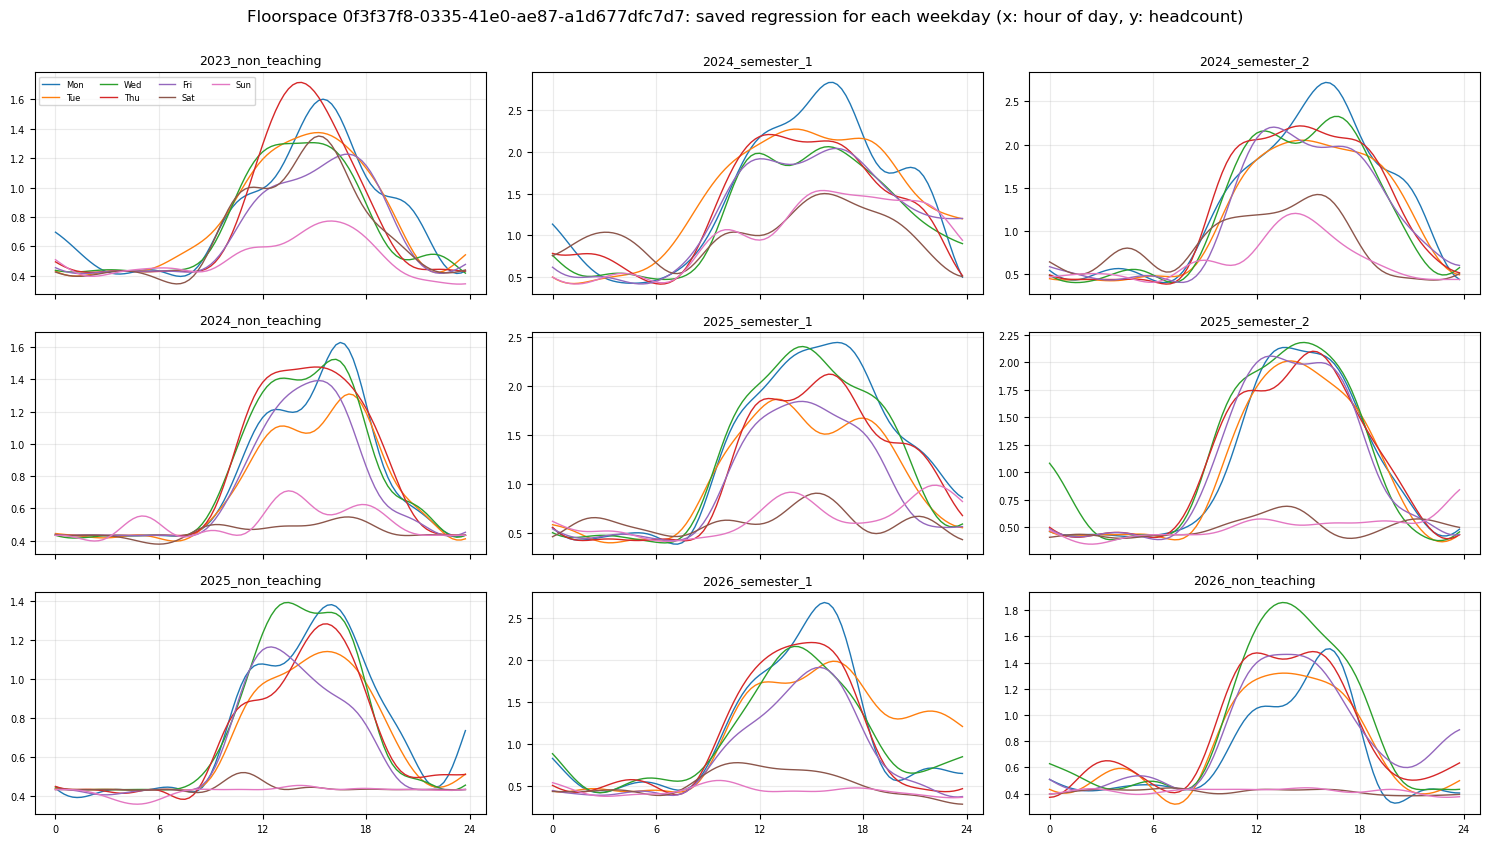

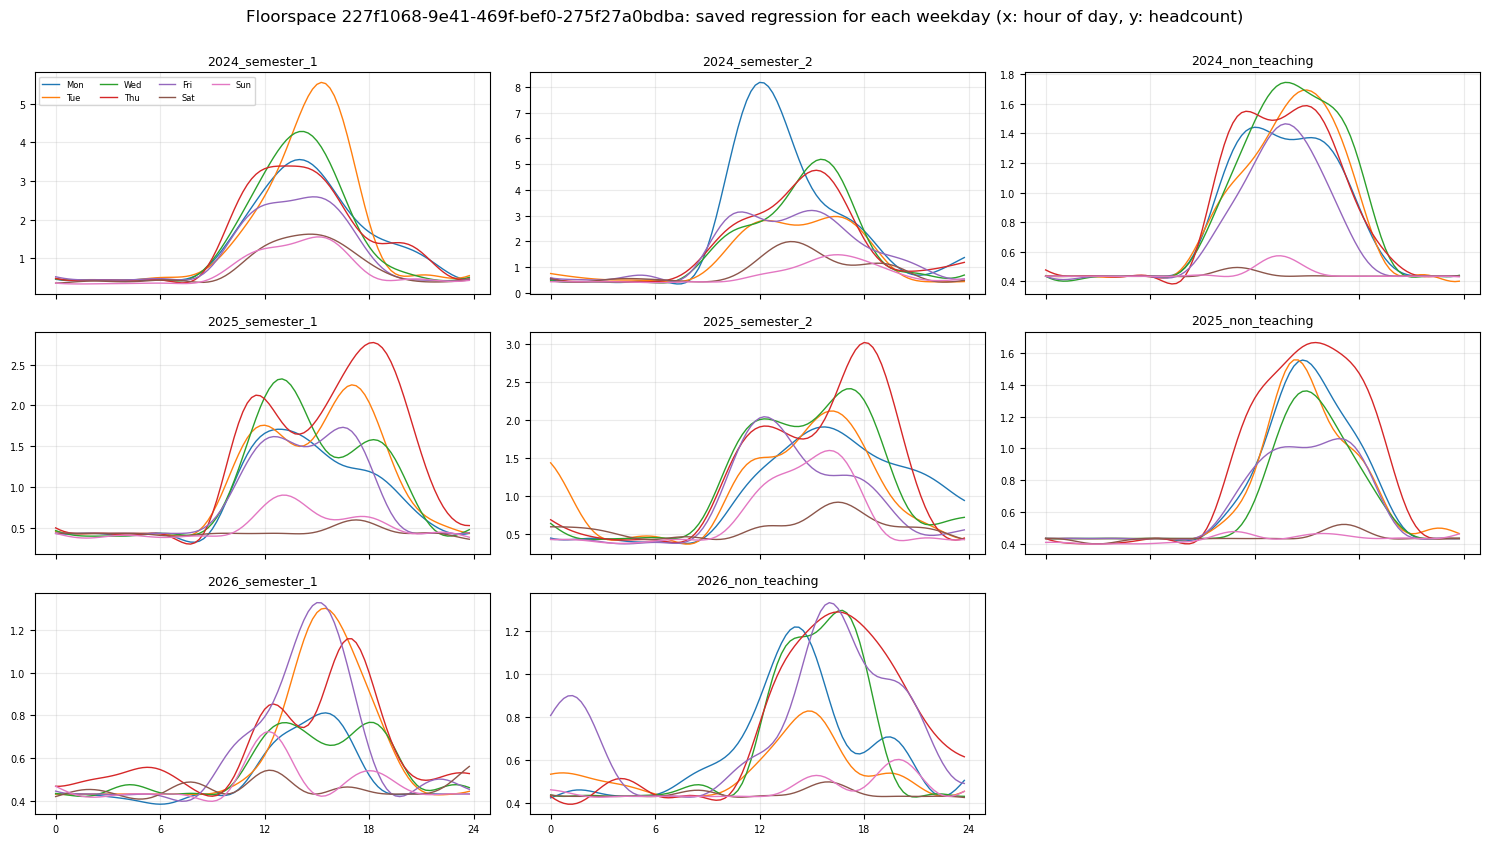

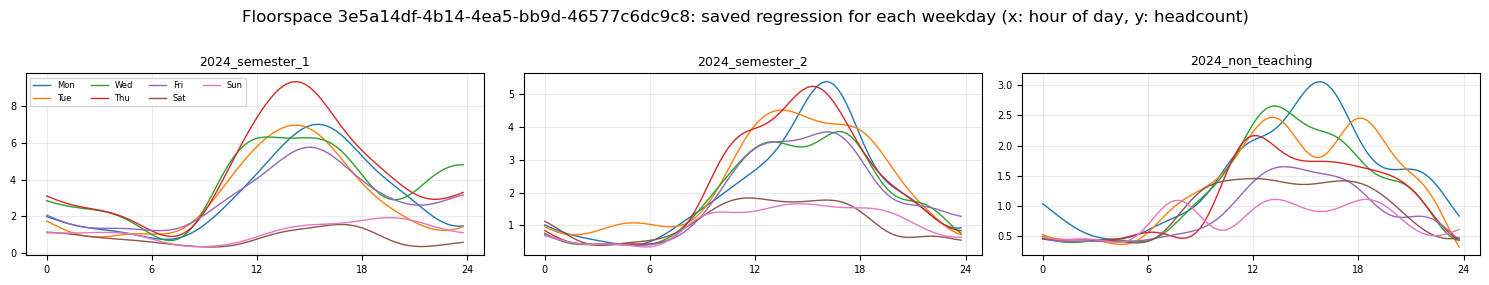

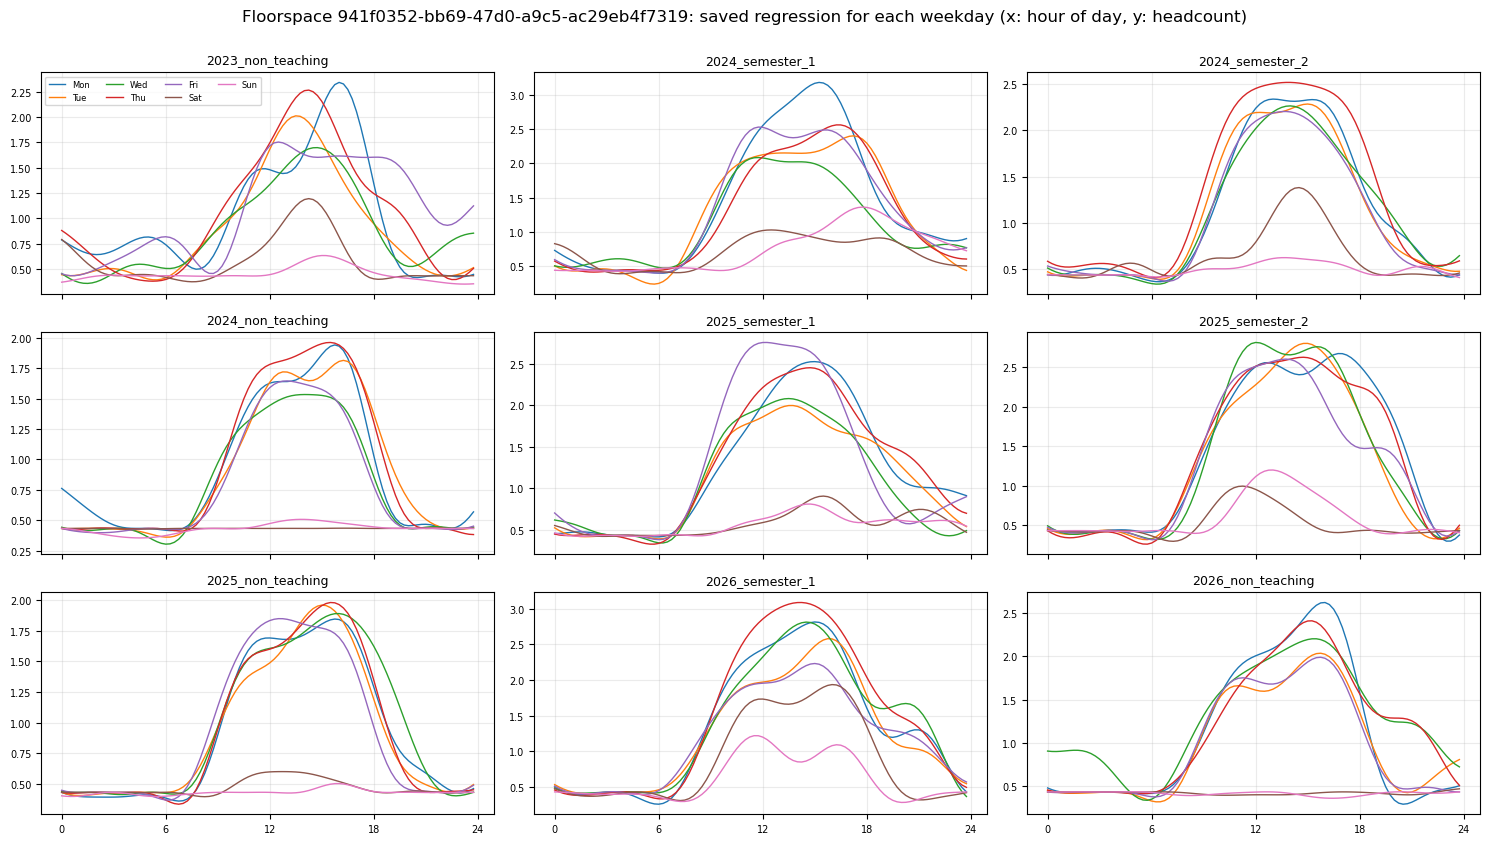

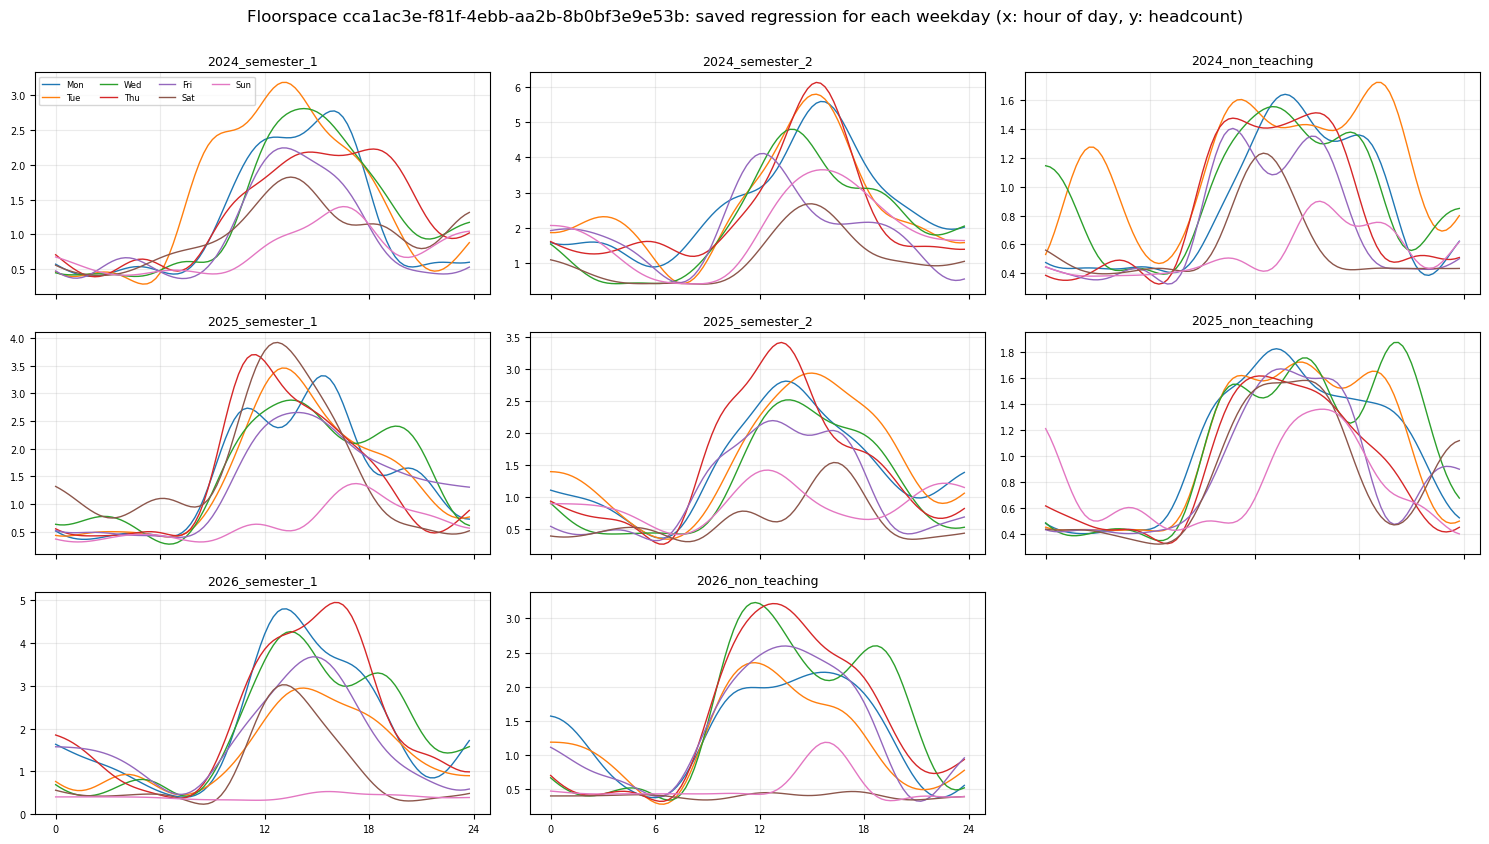

In [133]:
# Check the fit by eye for every saved model, drawn from the saved models only (no raw data needed).
# One figure per room, one panel per year and period.
# Dots are not drawn: only the saved regressions are, one coloured line per weekday.

import matplotlib.pyplot as plt
import numpy as np

for room_folder in sorted(p for p in MODELS_DIR.iterdir() if p.is_dir()):
    model_files = sorted((f for f in room_folder.glob("*.csv") if f.stem.split("_", 1)[0].isdigit() and f.stem[5:] in PERIOD_NAMES),
                         key=lambda f: (f.stem[:4], PERIOD_NAMES.index(f.stem[5:])))
    if not model_files:
        continue
    columns = 3
    rows = -(-len(model_files) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(15, 2.8 * rows), squeeze=False, sharex=True)
    for ax in axes.ravel()[len(model_files):]:
        ax.axis("off")
    grid = np.arange(0, 24, 0.25)
    for ax, model_file in zip(axes.ravel(), model_files):
        model = pd.read_csv(model_file)
        for weekday in sorted(model["weekday"].unique()):
            heights = [evaluate_model(model, pd.Timestamp(2024, 1, 1 + int(weekday), int(h), int(h % 1 * 60))) for h in grid]
            ax.plot(grid, heights, linewidth=1, label=WEEKDAYS[int(weekday)][:3])
        ax.set_title(model_file.stem, fontsize=9)
        ax.set_xticks(range(0, 25, 6))
        ax.tick_params(labelsize=7)
        ax.grid(True, alpha=0.25)
    axes[0][0].legend(fontsize=6, ncol=4)
    fig.suptitle(f"Floorspace {room_folder.name}: saved regression for each weekday (x: hour of day, y: headcount)", y=1.0)
    fig.tight_layout()
    plt.show()

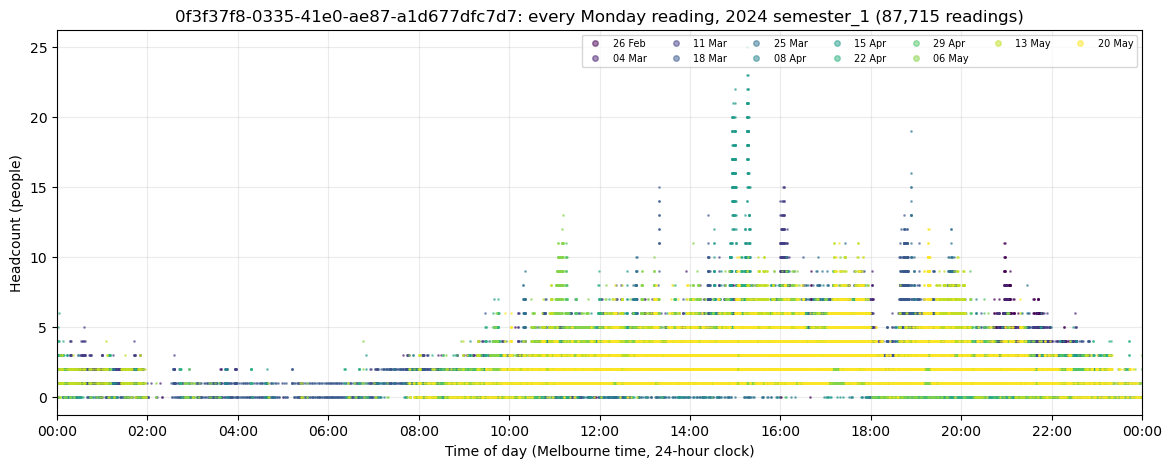

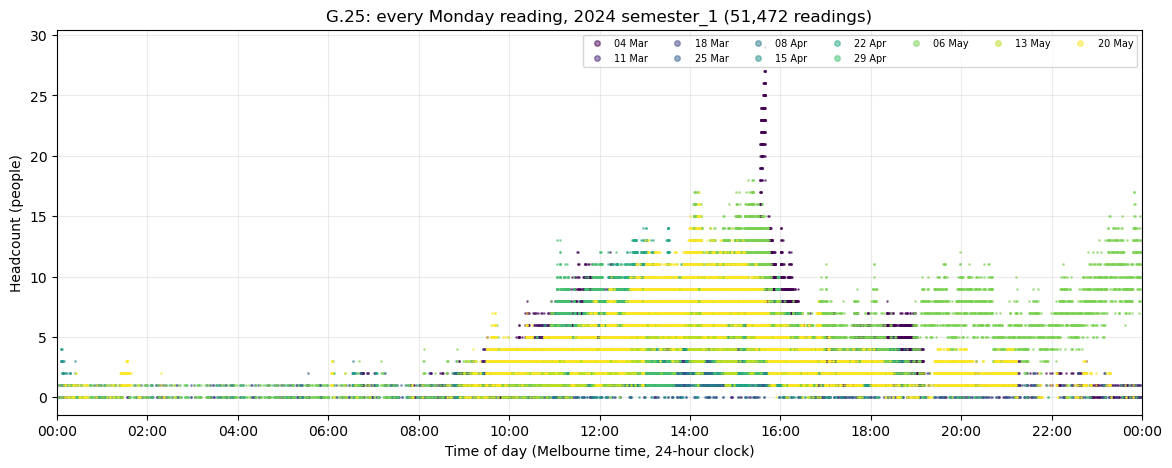

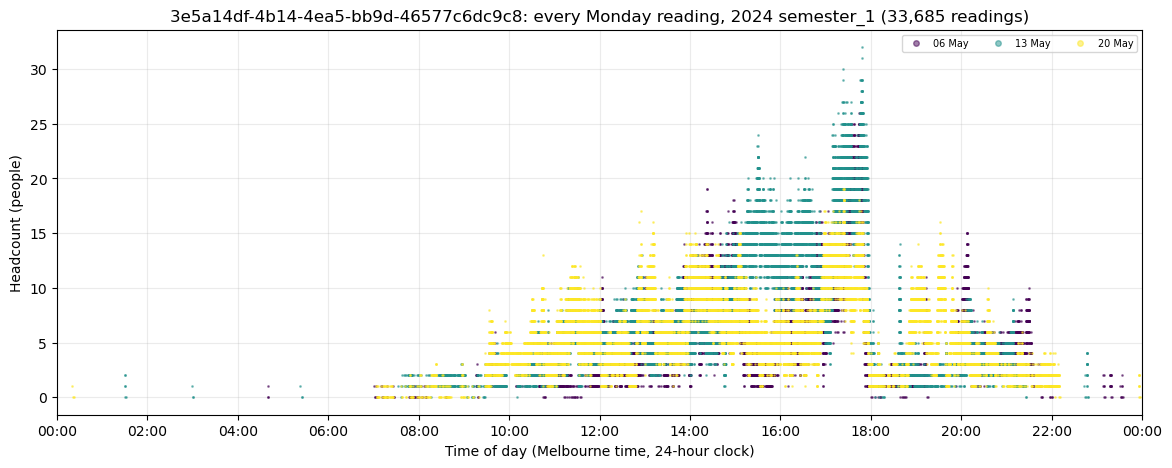

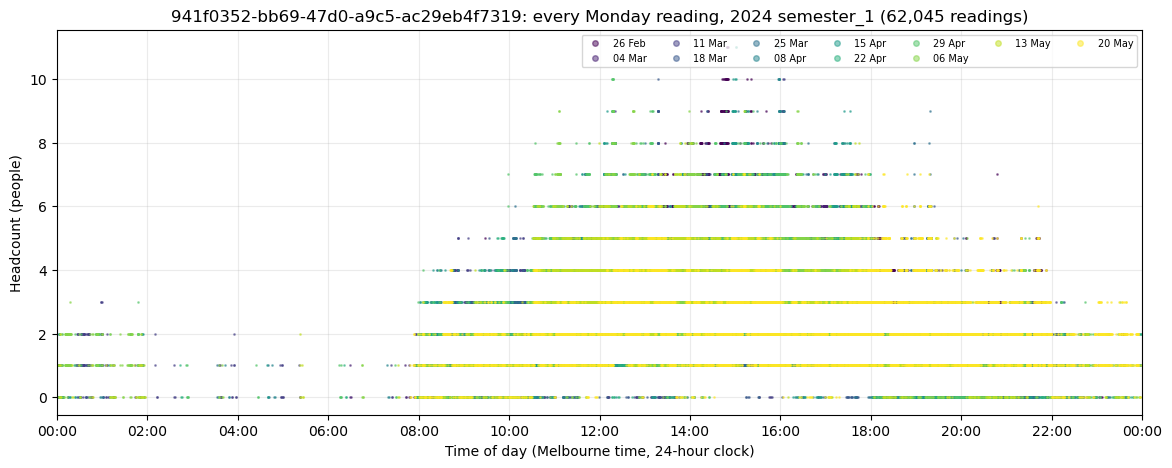

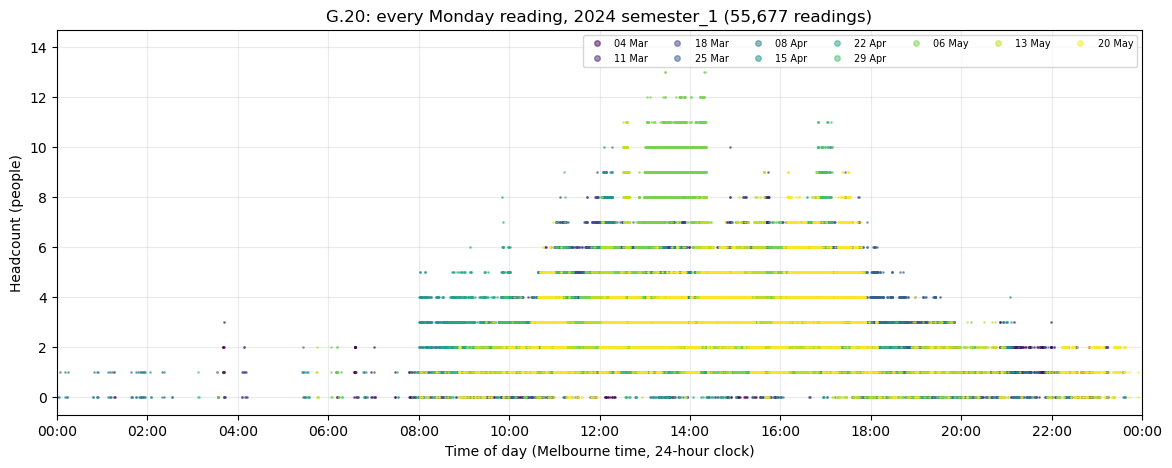

In [134]:
# Every raw reading from every Monday of Semester 1 2024, one figure per room.
# The x-axis is the time of day; each Monday is its own colour, so the week-to-week spread in a slot is visible.
PLOT_YEAR, PLOT_PERIOD, PLOT_WEEKDAY = 2024, "semester_1", 0   # 0 = Monday

import matplotlib.pyplot as plt
import numpy as np

plot_calendar = read_semester_calendar([Path.cwd(), DATA_DIR])
plot_lookup = read_lookup(LOOKUP_FOLDERS)
streams_dir = OUTPUT_DIR / "occupancy_streams"
for stream_file in sorted(streams_dir.glob("*.csv")):
    if stream_file.stem == "rows_per_room":
        continue
    data, times = read_room_data(stream_file.stem, streams_dir)
    headcounts = pd.to_numeric(data["headcount"], errors="coerce")
    chosen = ((label_periods(times, plot_calendar) == PLOT_PERIOD) & (times.dt.year == PLOT_YEAR)
              & (times.dt.dayofweek == PLOT_WEEKDAY) & headcounts.notna())
    if not chosen.any():
        continue
    days = times[chosen].dt.tz_localize(None)
    hours = (days - days.dt.normalize()).dt.total_seconds() / 3600
    dates = days.dt.normalize()
    fig, ax = plt.subplots(figsize=(14, 5))
    colours = plt.cm.viridis(np.linspace(0, 1, dates.nunique()))
    for colour, (date, group) in zip(colours, hours.groupby(dates)):
        ax.plot(group, headcounts[chosen][group.index], ".", markersize=2, color=colour, alpha=0.5, label=date.strftime("%d %b"))
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 2), [f"{h % 24:02d}:00" for h in range(0, 25, 2)])
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.set_xlabel("Time of day (Melbourne time, 24-hour clock)")
    ax.set_ylabel("Headcount (people)")
    room_names = sorted(set(plot_lookup.loc[plot_lookup["id"] == stream_file.stem, "entry"]))
    ax.set_title(f"{' / '.join(room_names) or stream_file.stem}: every {WEEKDAYS[PLOT_WEEKDAY]} reading, {PLOT_YEAR} {PLOT_PERIOD} ({chosen.sum():,} readings)")
    ax.legend(ncol=7, fontsize=7, markerscale=4, loc="upper right")
    ax.grid(True, alpha=0.25)
    plt.show()

## Scoring the models

The models above are one RBF support-vector regression per room, year, period and weekday, with the fixed settings chosen in
`archive\investigations\05_svr_vs_tree_tuning`. The next cell scores them by cross-validation that holds out whole dates, against a
constant-median baseline, then plots each fit over the slot means it was trained on. A weekday needs at least 3 dates;
with fewer it is reported as `not scored`.

In [135]:
def score_svr(slots):
    """Score the regression on dates it has not seen, against a constant-median baseline.

    The dates are shared out at random (fixed seed) between folds; each fold's dates are predicted by a regression trained on
    the other folds, so no date is both trained and tested on.

    Input:
        slots: the table made by slot_means (one room, year, period and weekday).

    Output:
        A pair (svr_mae, median_mae): the mean absolute error of the regression and of predicting the training median.
        None if there are fewer than SVR_MIN_DATES dates.
    """
    dates = slots.date.to_numpy()
    days = np.unique(dates)
    if len(days) < SVR_MIN_DATES:
        return None
    folds = min(SVR_FOLDS, len(days))
    fold_of = dict(zip(days[np.random.default_rng(1).permutation(len(days))], np.arange(len(days)) % folds))
    fold = np.array([fold_of[d] for d in dates])
    hours, counts = slots.hour.to_numpy(), slots.headcount.to_numpy()
    svr_error, median_error = np.empty(len(slots)), np.empty(len(slots))
    for f in range(folds):
        test = fold == f
        svr_error[test] = np.abs(predict_svr(fit_svr(hours[~test], counts[~test]), hours[test]) - counts[test])
        median_error[test] = np.abs(np.median(counts[~test]) - counts[test])
    return float(svr_error.mean()), float(median_error.mean())

Scored 259 subsets (0 had too few dates). Mean MAE (people), SVR vs constant median:
                       subsets  svr_mae  median_mae  svr_wins
room     period                                              
0f3f37f8 semester_1         21    0.569       0.703        18
         semester_2         14    0.663       0.828        12
         non_teaching       28    0.454       0.505        22
3e5a14df semester_1          7    1.865       2.369         5
         semester_2          7    1.047       1.472         7
         non_teaching        7    0.937       1.002         6
941f0352 semester_1         21    0.561       0.764        19
         semester_2         14    0.547       0.777        12
         non_teaching       28    0.510       0.628        20
G.20     semester_1         21    1.242       1.448        19
         semester_2         14    1.879       2.047        14
         non_teaching       21    1.016       1.070        19
G.25     semester_1         21    0.673       0

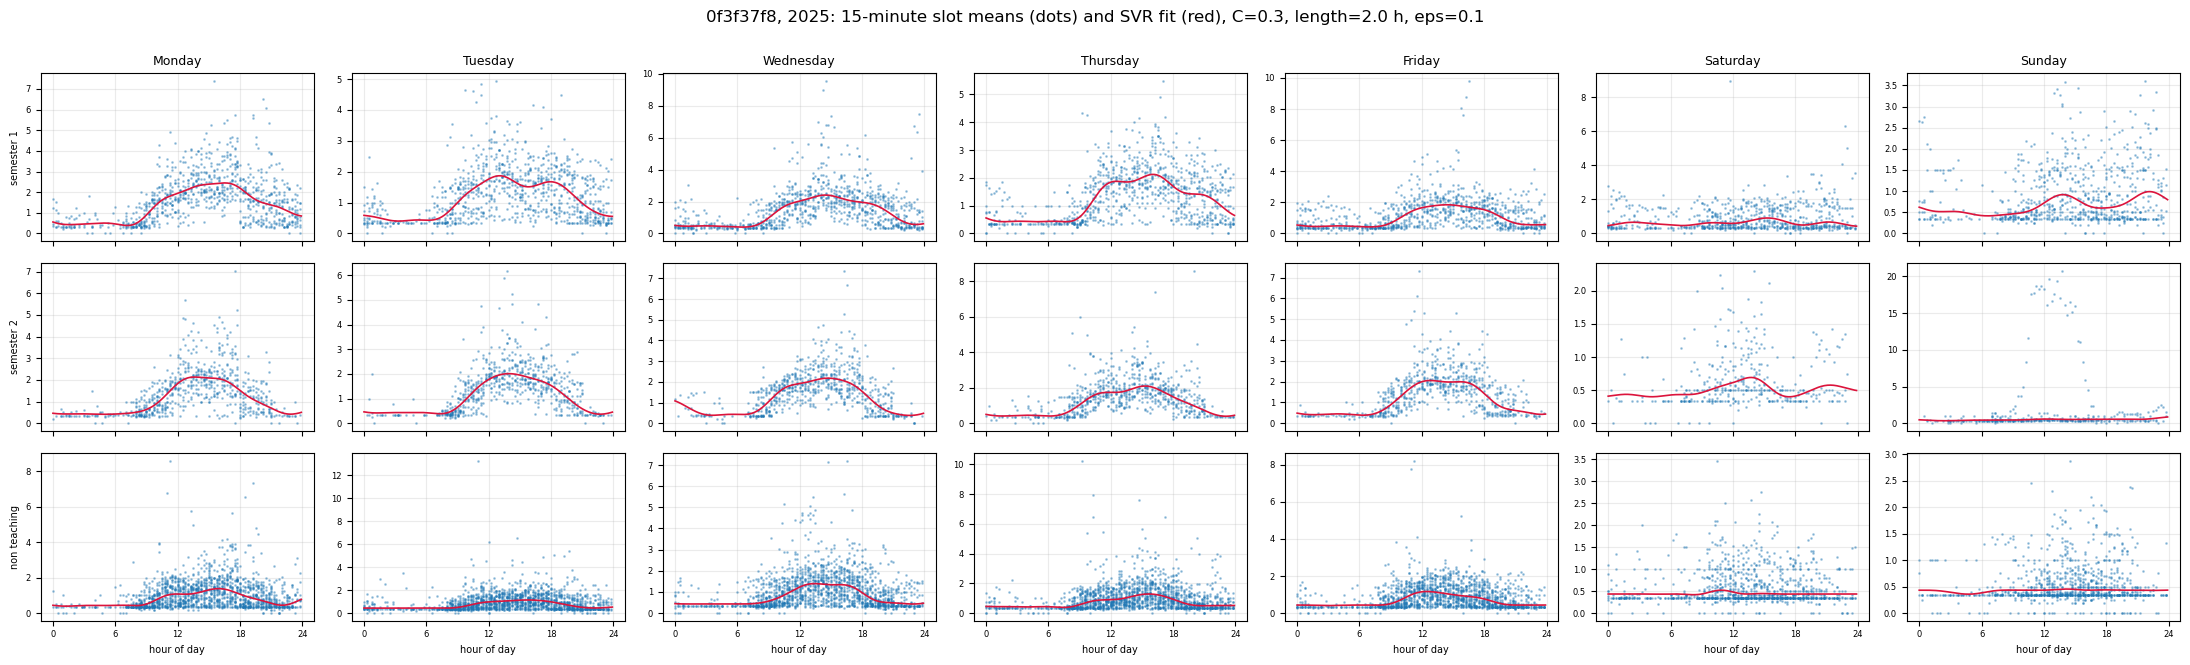

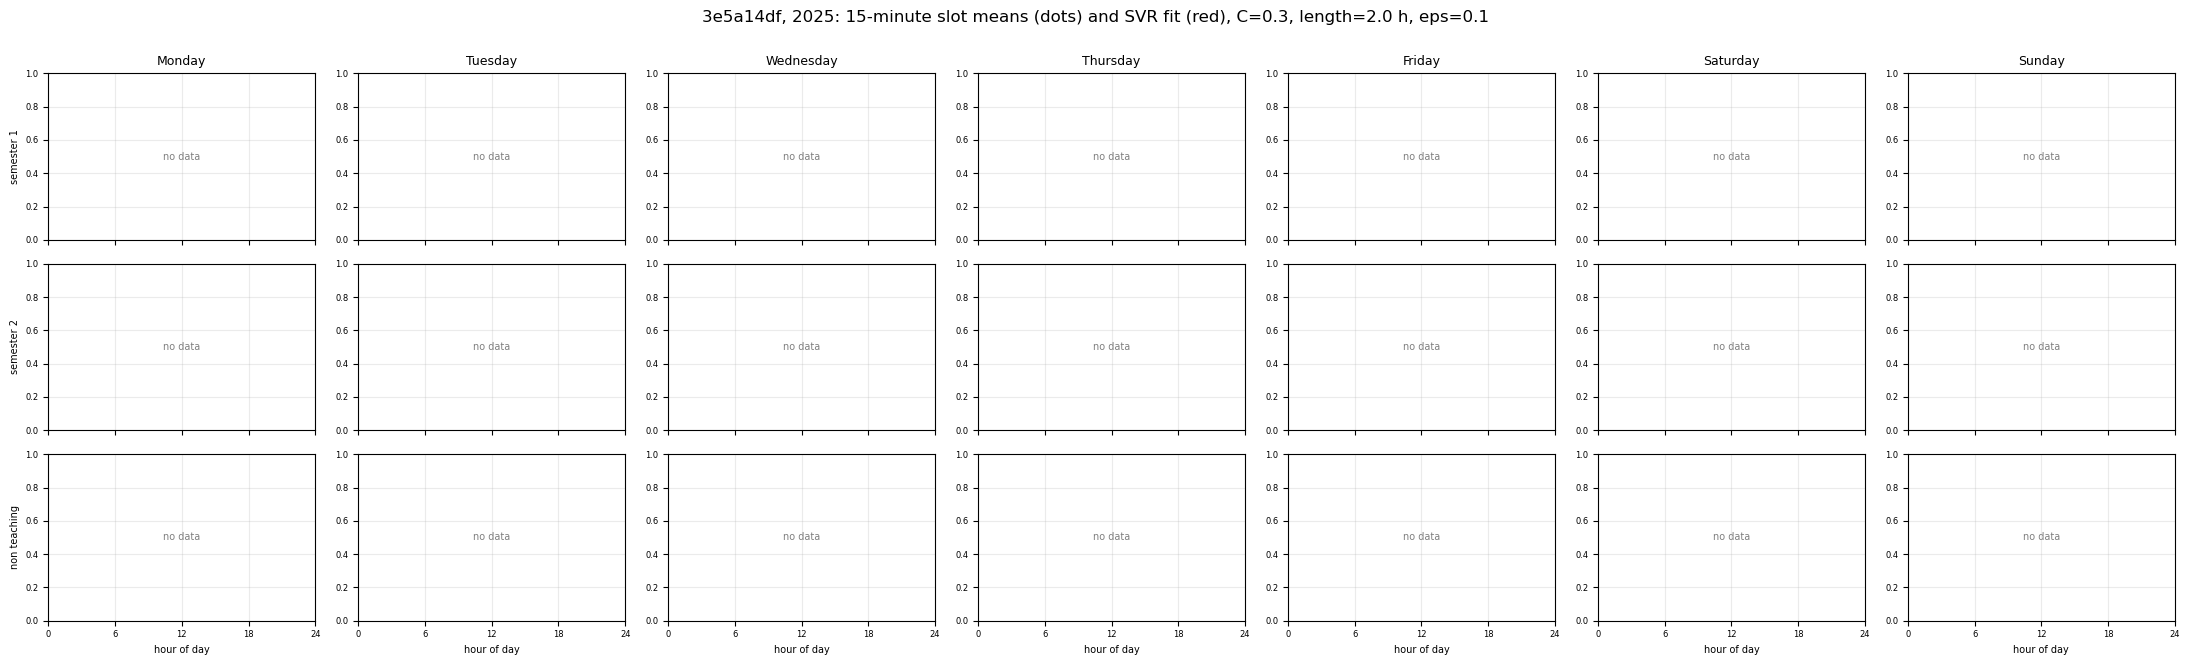

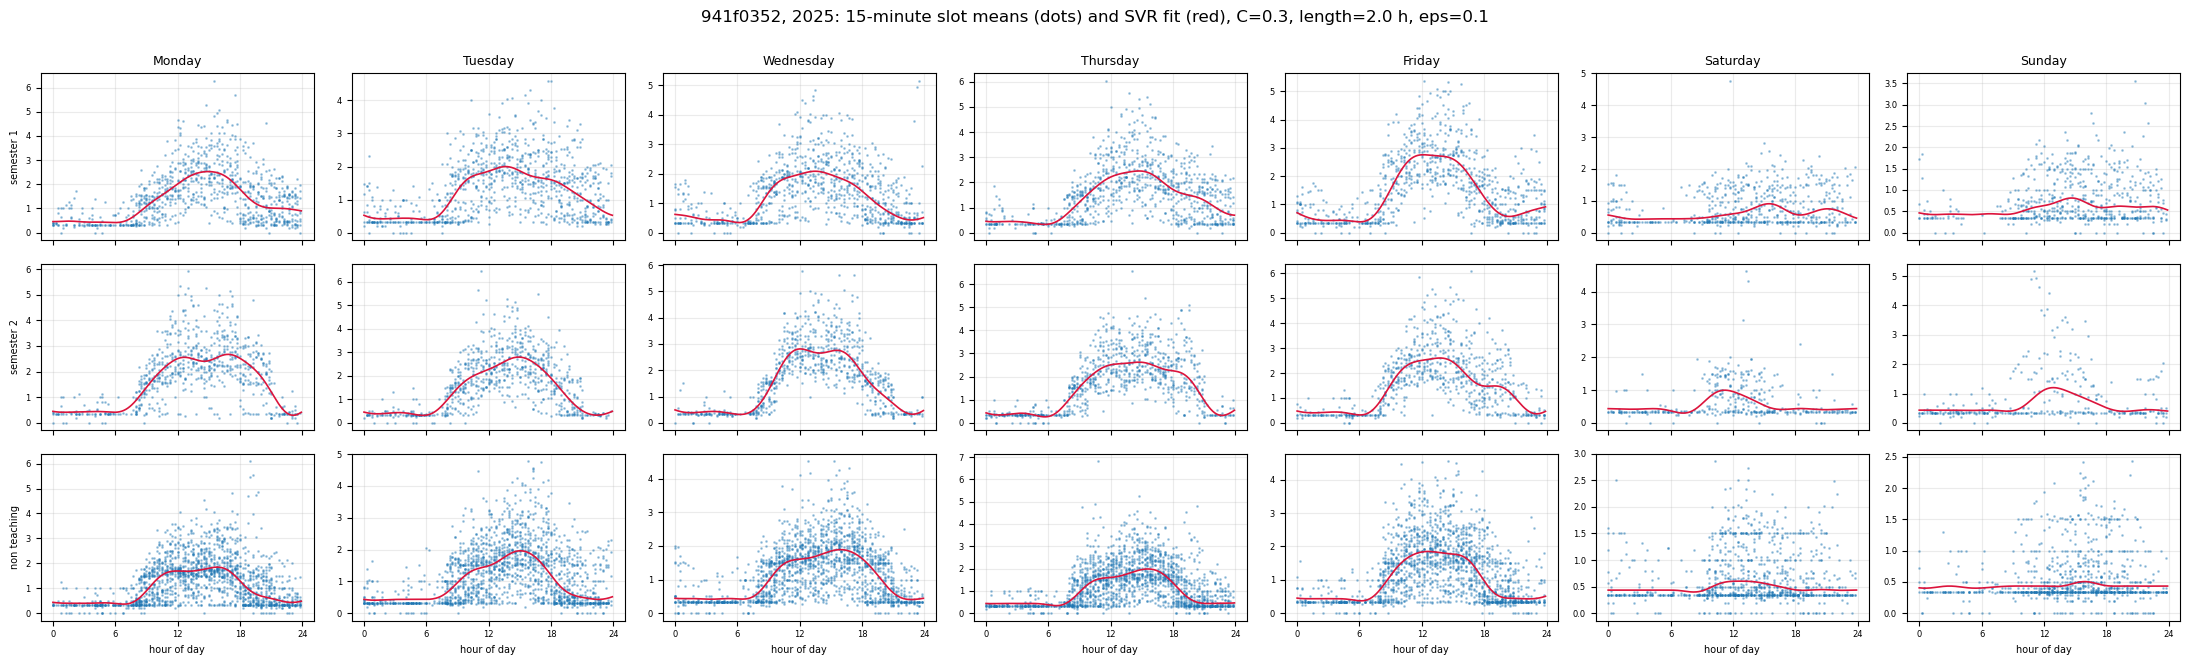

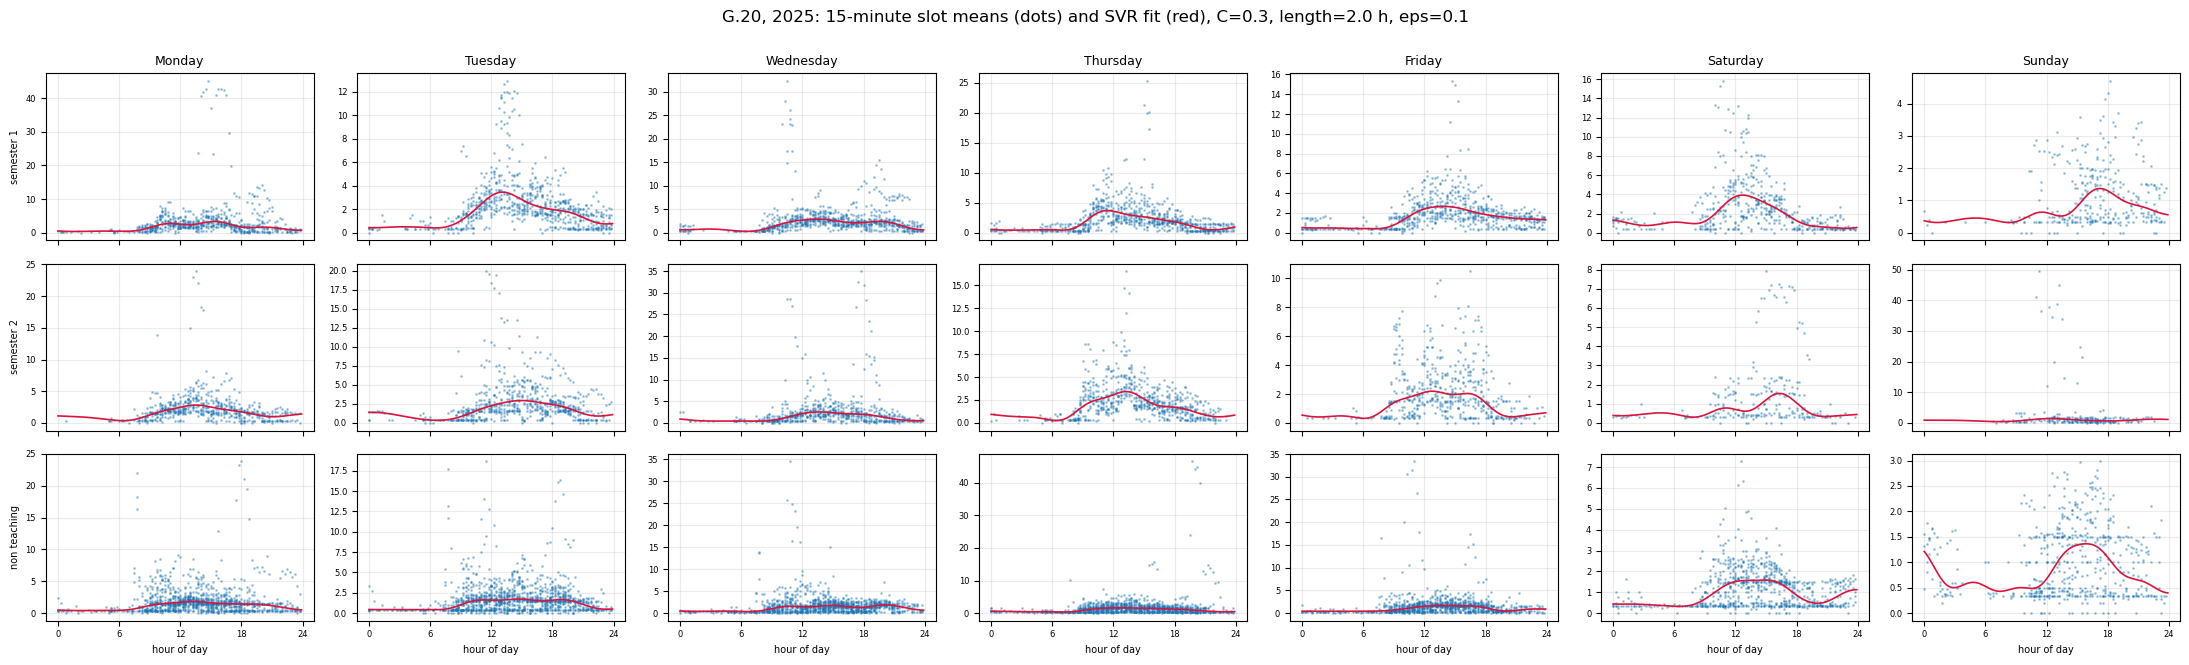

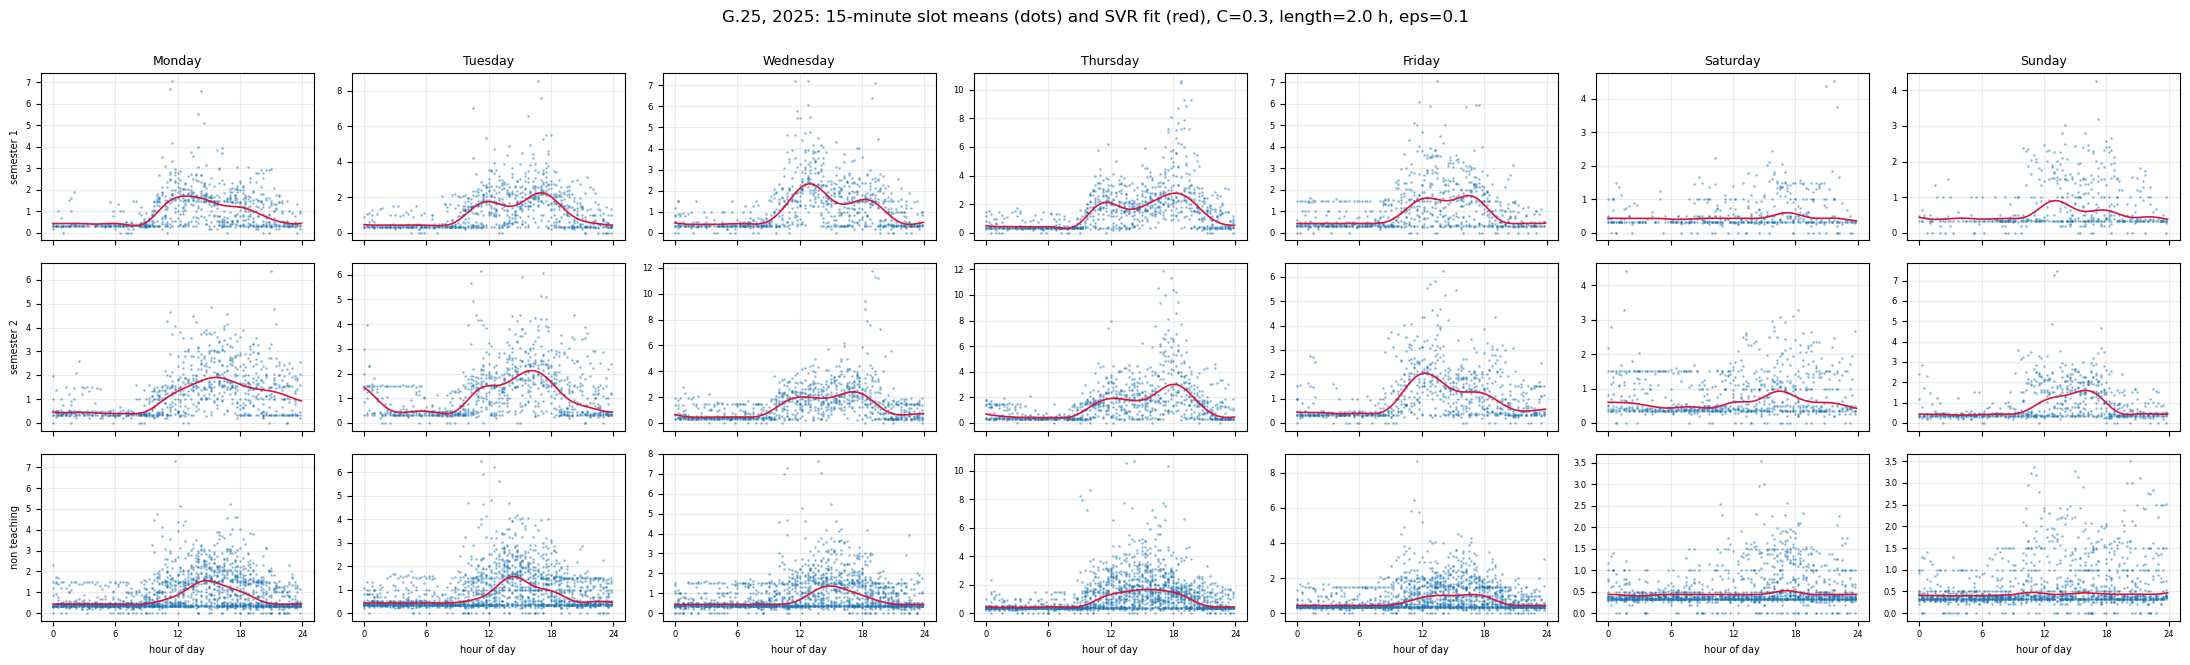

In [136]:
import matplotlib.pyplot as plt
import numpy as np

SVR_PLOT_YEAR = 2025      # the year drawn in the grid of plots (every year is scored in the table)

svr_calendar = read_semester_calendar([Path.cwd(), DATA_DIR])
svr_lookup = read_lookup(LOOKUP_FOLDERS)
svr_streams = OUTPUT_DIR / "occupancy_streams"
named_ids = sorted(ids_in_folder(svr_streams))   # every room in the data; unnamed ones are labelled by their ID

scores, fits = [], {}
for room_id in named_ids:
    room = " / ".join(sorted(set(svr_lookup.loc[svr_lookup["id"] == room_id, "entry"]))) or room_id[:8]
    data, times = read_room_data(room_id, svr_streams)
    counts = pd.to_numeric(data["headcount"], errors="coerce")
    labels = label_periods(times, svr_calendar)
    for year in sorted(times.dt.year.unique()):
        if year not in svr_calendar:
            continue
        for period in PERIOD_NAMES:
            for weekday in range(7):
                chosen = ((labels == period) & (times.dt.year == year) & (times.dt.dayofweek == weekday) & counts.notna()).to_numpy()
                if not chosen.any():
                    continue
                slots = slot_means(times[chosen], counts[chosen])
                result = score_svr(slots)
                group = WEEKDAYS[weekday][:3]
                row = {"room": room, "year": year, "period": period, "weekday": group,
                       "dates": slots.date.nunique(), "svr_mae": None, "median_mae": None}
                if result is None:
                    row["note"] = "not scored (too few dates)"
                else:
                    row["svr_mae"], row["median_mae"] = result
                    fits[(room, year, period, group)] = (fit_svr(slots.hour, slots.headcount), slots)
                scores.append(row)

scores = pd.DataFrame(scores)
scored = scores.dropna(subset=["svr_mae"]).copy()
scored["beats_median"] = scored.svr_mae < scored.median_mae
print(f"Scored {len(scored)} subsets ({len(scores) - len(scored)} had too few dates). Mean MAE (people), SVR vs constant median:")
by_period = scored.groupby(["room", "period"]).agg(subsets=("svr_mae", "size"), svr_mae=("svr_mae", "mean"),
                                                   median_mae=("median_mae", "mean"), svr_wins=("beats_median", "sum"))
print(by_period.reindex(PERIOD_NAMES, level="period").round(3).to_string())
print("\nBy weekday:")
print(scored.groupby(["room", "weekday"]).agg(subsets=("svr_mae", "size"), svr_mae=("svr_mae", "mean"), median_mae=("median_mae", "mean"))
      .round(3).to_string())
print(f"\nOverall: SVR {scored.svr_mae.mean():.3f}, median {scored.median_mae.mean():.3f}; SVR is better in {scored.beats_median.sum()} of {len(scored)} subsets.")
print("Full per-subset table: the variable `scores`.")

# Plot: for each room, rows are periods and columns are weekdays; dots are slot means, one per date, the line is the fitted SVR.
grid_hours = np.arange(0, 24, 0.1)
for room in sorted({key[0] for key in fits}):
    fig, axes = plt.subplots(len(PERIOD_NAMES), 7, figsize=(22, 2.2 * len(PERIOD_NAMES)), sharex=True, squeeze=False)
    for r, period in enumerate(PERIOD_NAMES):
        for column in range(7):
            ax = axes[r][column]
            ax.grid(True, alpha=0.25)
            ax.tick_params(labelsize=6)
            if r == 0:
                ax.set_title(WEEKDAYS[column], fontsize=9)
            key = (room, SVR_PLOT_YEAR, period, WEEKDAYS[column][:3])
            if key not in fits:
                ax.text(0.5, 0.5, "no data", ha="center", va="center", fontsize=7, color="grey", transform=ax.transAxes)
                continue
            fitted, slots = fits[key]
            ax.plot(slots.hour, slots.headcount, ".", markersize=2, alpha=0.35)
            ax.plot(grid_hours, predict_svr(fitted, grid_hours), color="crimson", linewidth=1.2)
    for column in range(7):
        axes[-1][column].set_xticks(range(0, 25, 6))
        axes[-1][column].set_xlabel("hour of day", fontsize=7)
    for r, period in enumerate(PERIOD_NAMES):
        axes[r][0].set_ylabel(period.replace("_", " "), fontsize=7)
    fig.suptitle(f"{room}, {SVR_PLOT_YEAR}: 15-minute slot means (dots) and SVR fit (red), C={SVR_C}, length={SVR_LENGTH_HOURS} h, eps={SVR_EPSILON}", y=1.0)
    fig.tight_layout()
    plt.show()